In [ ]:
!cp -r /content/drive/MyDrive/deep-past-initiative-machine-translation.zip  /content/deep-past-initiative-machine-translation.zip

In [ ]:
!unzip /content/deep-past-initiative-machine-translation.zip

Archive:  /content/deep-past-initiative-machine-translation.zip
  inflating: OA_Lexicon_eBL.csv      
  inflating: Sentences_Oare_FirstWord_LinNum.csv  
  inflating: bibliography.csv        
  inflating: eBL_Dictionary.csv      
  inflating: publications.csv        
  inflating: published_texts.csv     
  inflating: resources.csv           
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


Loading datasets...

Train dataset shape: (1561, 3)
Test dataset shape: (4, 5)

Train columns: ['oare_id', 'transliteration', 'translation']

Sample training data:
                                oare_id  \
0  004a7dbd-57ce-46f8-9691-409be61c676e   
1  0064939c-59b9-4448-a63d-34612af0a1b5   
2  0073f2c0-524c-4bbf-915a-8c1772a4fb98   

                                     transliteration  \
0  KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-(d)IM KIŠI...   
1               1 TÚG ša qá-tim i-tur₄-DINGIR il₅-qé   
2  TÚG u-la i-dí-na-ku-um i-tù-ra-ma 9 GÍN KÙ.BABBAR   

                                         translation  
0  Seal of Mannum-balum-Aššur son of Ṣilli-Adad, ...  
1  Itūr-ilī has received one textile of ordinary ...  
2  ... he did not give you a textile. He returned...  

Loading MADLAD400 tokenizer...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]


Tokenizing data to analyze length distribution...

TOKEN LENGTH STATISTICS

📊 SOURCE (Transliteration) Token Lengths:
  Mean:   265.07
  Median: 228.00
  Std:    165.97
  Min:    17
  Max:    635
  75th percentile: 393
  90th percentile: 540
  95th percentile: 553
  99th percentile: 580

📊 TARGET (Translation) Token Lengths:
  Mean:   157.85
  Median: 123.00
  Std:    144.43
  Min:    4
  Max:    1267
  75th percentile: 211
  90th percentile: 317
  95th percentile: 415
  99th percentile: 717

RECOMMENDED MAX_LENGTH SETTINGS

✅ Recommended MAX_LENGTH (covers 95% of data): 553
   - This will truncate ~5% of samples
   - Good balance between coverage and efficiency

⚠️  Conservative MAX_LENGTH (covers 99% of data): 717
   - This will truncate only ~1% of samples
   - Uses more memory but better coverage

🔥 Aggressive MAX_LENGTH (covers 90% of data): 540
   - Fastest training, lowest memory
   - May truncate important content

OUTLIER ANALYSIS

Samples with source length > 95th percentile

/tmp/ipython-input-3361254458.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])



✅ Visualization saved as 'token_length_distribution.png'


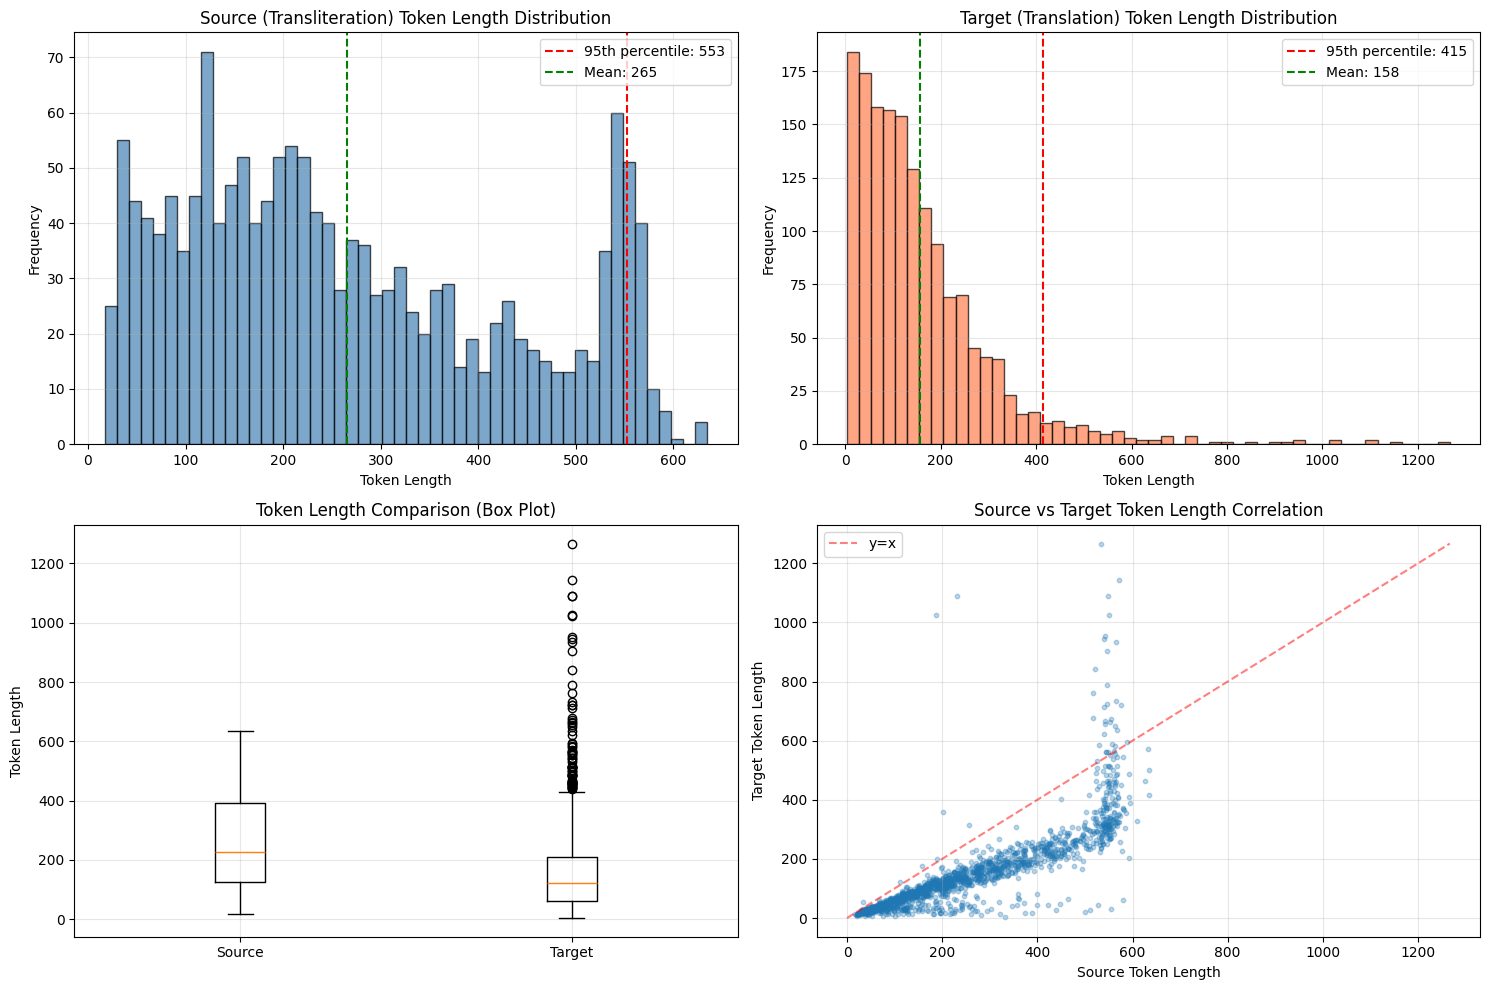


SUMMARY & RECOMMENDATIONS

Based on the analysis:

1. Use MAX_LENGTH = 553 in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - ⚠️  Consider adjusting based on your data

3. Samples that will be truncated at 512 tokens:
   - Source: 222 samples (14.22%)
   - Target: 44 samples (2.82%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "google/madlad400-3b-mt"
INPUT_DIR = "/content/"
TRAIN_CSV = f"{INPUT_DIR}/train.csv"
TEST_CSV = f"{INPUT_DIR}/test.csv"

# ==================== 1. LOAD DATA ====================
print("Loading datasets...")
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)

print(f"\nTrain dataset shape: {train.shape}")
print(f"Test dataset shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")

# Display sample data
print("\n" + "="*50)
print("Sample training data:")
print("="*50)
print(train.head(3))

# ==================== 2. LOAD TOKENIZER ====================
print("\n" + "="*50)
print("Loading MADLAD400 tokenizer...")
print("="*50)
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)

# MADLAD400 uses language code prefix (e.g., "<2en>" for English target)
PREFIX = "<2en> "

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("\nTokenizing data to analyze length distribution...")

# Tokenize source (transliteration) with prefix
source_lengths = train['transliteration'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# Tokenize target (translation)
target_lengths = train['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS ====================
print("\n" + "="*50)
print("TOKEN LENGTH STATISTICS")
print("="*50)

print("\n📊 SOURCE (Transliteration) Token Lengths:")
print(f"  Mean:   {source_lengths.mean():.2f}")
print(f"  Median: {source_lengths.median():.2f}")
print(f"  Std:    {source_lengths.std():.2f}")
print(f"  Min:    {source_lengths.min()}")
print(f"  Max:    {source_lengths.max()}")
print(f"  75th percentile: {source_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {source_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {source_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {source_lengths.quantile(0.99):.0f}")

print("\n📊 TARGET (Translation) Token Lengths:")
print(f"  Mean:   {target_lengths.mean():.2f}")
print(f"  Median: {target_lengths.median():.2f}")
print(f"  Std:    {target_lengths.std():.2f}")
print(f"  Min:    {target_lengths.min()}")
print(f"  Max:    {target_lengths.max()}")
print(f"  75th percentile: {target_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {target_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {target_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {target_lengths.quantile(0.99):.0f}")

# ==================== 5. RECOMMENDED MAX_LENGTH ====================
print("\n" + "="*50)
print("RECOMMENDED MAX_LENGTH SETTINGS")
print("="*50)

# Calculate suggested max_length based on percentiles
source_95 = int(source_lengths.quantile(0.95))
target_95 = int(target_lengths.quantile(0.95))
source_99 = int(source_lengths.quantile(0.99))
target_99 = int(target_lengths.quantile(0.99))

suggested_max_length = max(source_95, target_95)
conservative_max_length = max(source_99, target_99)

print(f"\n✅ Recommended MAX_LENGTH (covers 95% of data): {suggested_max_length}")
print(f"   - This will truncate ~5% of samples")
print(f"   - Good balance between coverage and efficiency")

print(f"\n⚠️  Conservative MAX_LENGTH (covers 99% of data): {conservative_max_length}")
print(f"   - This will truncate only ~1% of samples")
print(f"   - Uses more memory but better coverage")

print(f"\n🔥 Aggressive MAX_LENGTH (covers 90% of data): {max(int(source_lengths.quantile(0.90)), int(target_lengths.quantile(0.90)))}")
print(f"   - Fastest training, lowest memory")
print(f"   - May truncate important content")

# ==================== 6. CHECK OUTLIERS ====================
print("\n" + "="*50)
print("OUTLIER ANALYSIS")
print("="*50)

# Find samples with very long sequences
threshold = source_lengths.quantile(0.95)
long_sources = train[source_lengths > threshold]

print(f"\nSamples with source length > 95th percentile ({threshold:.0f} tokens): {len(long_sources)}")
if len(long_sources) > 0:
    print("\nExamples of long transliterations:")
    for idx in long_sources.head(3).index:
        src_len = source_lengths.iloc[idx]
        print(f"\n  Index {idx} (Length: {src_len} tokens):")
        print(f"  {train.loc[idx, 'transliteration'][:200]}...")

# ==================== 7. VISUALIZATIONS ====================
print("\n" + "="*50)
print("GENERATING VISUALIZATIONS")
print("="*50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Source length distribution
axes[0, 0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(source_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {source_lengths.quantile(0.95):.0f}')
axes[0, 0].axvline(source_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {source_lengths.mean():.0f}')
axes[0, 0].set_xlabel('Token Length')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Source (Transliteration) Token Length Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Target length distribution
axes[0, 1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(target_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {target_lengths.quantile(0.95):.0f}')
axes[0, 1].axvline(target_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {target_lengths.mean():.0f}')
axes[0, 1].set_xlabel('Token Length')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Target (Translation) Token Length Distribution')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot comparison
data_to_plot = [source_lengths, target_lengths]
axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])
axes[1, 0].set_ylabel('Token Length')
axes[1, 0].set_title('Token Length Comparison (Box Plot)')
axes[1, 0].grid(alpha=0.3)

# Scatter plot: source vs target length
axes[1, 1].scatter(source_lengths, target_lengths, alpha=0.3, s=10)
axes[1, 1].set_xlabel('Source Token Length')
axes[1, 1].set_ylabel('Target Token Length')
axes[1, 1].set_title('Source vs Target Token Length Correlation')
axes[1, 1].grid(alpha=0.3)

# Add diagonal reference line
max_val = max(source_lengths.max(), target_lengths.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', alpha=0.5, label='y=x')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('token_length_distribution.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved as 'token_length_distribution.png'")
plt.show()

# ==================== 8. SUMMARY ====================
print("\n" + "="*50)
print("SUMMARY & RECOMMENDATIONS")
print("="*50)
print(f"""
Based on the analysis:

1. Use MAX_LENGTH = {suggested_max_length} in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - {'✅ This is sufficient!' if 512 >= suggested_max_length else '⚠️  Consider adjusting based on your data'}

3. Samples that will be truncated at 512 tokens:
   - Source: {(source_lengths > 512).sum()} samples ({(source_lengths > 512).sum() / len(source_lengths) * 100:.2f}%)
   - Target: {(target_lengths > 512).sum()} samples ({(target_lengths > 512).sum() / len(target_lengths) * 100:.2f}%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.
""")

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.9 MB/s eta 0:00:00


In [ ]:
!pip install sacrebleu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 8.9 MB/s eta 0:00:00


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from sentence_transformers import SentenceTransformer, util
import evaluate

class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576
    BATCH_SIZE = 4
    EPOCHS = 3
    LEARNING_RATE = 1e-4
    OUTPUT_DIR = "./madlad400-3b-akkadian"


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")


def simple_sentence_aligner(df):
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


train_expanded = simple_sentence_aligner(train_df)
print(f"Expanded Train Data: {len(train_expanded)} sentences (Alignment applied)")

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)


# ==========================================
# Tokenization & preprocessing
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    # FIX 1: Clip predictions to valid token range
    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)

    # FIX 2: Replace invalid tokens with pad token
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        # Fallback: decode one by one and skip problematic sequences
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")  # Empty string for failed decoding

    # Process labels
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",  # Changed to save checkpoints
    learning_rate=Config.LEARNING_RATE,

    fp16=False,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,

    # FIX 3: Add generation config to prevent overflow
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=4,

    logging_steps=10,
    report_to="none",

    greater_is_better=True,
    load_best_model_at_end=True,
    metric_for_best_model="chrf",

    lr_scheduler_type="cosine",
    warmup_steps=100,
    max_grad_norm=1.0,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,  # FIX 4: Use processing_class instead of tokenizer
    compute_metrics=compute_metrics
)

print("Starting Training with MADLAD400-3B-MT (FP32 mode)...")
trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model saved to {Config.OUTPUT_DIR}")

Expanded Train Data: 1561 sentences (Alignment applied)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (8 outputs left out)

Starting Training with MADLAD400-3B-MT (FP32 mode)...


Epoch,Training Loss,Validation Loss,Chrf
1,1.319700,1.297073,34.797976
2,0.892500,1.037243,48.393850
3,0.718000,1.013998,48.321484


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Model saved to ./madlad400-3b-akkadian


In [ ]:
!cp -r /content/madlad400-3b-akkadian/checkpoint-702/  /content/checkpoint-702/

In [ ]:
!rm /content/checkpoint-702/optimizer.pt

# this gave me 30.04 score

# bidirectional training

#madlab

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from sentence_transformers import SentenceTransformer, util
import evaluate

class Config:
    """Configuration for MADLAD400-3B Akkadian-to-English Machine Translation"""
    # ====== Model Configuration ======
    MODEL_NAME = "google/madlad400-3b-mt"
    PRETRAINED_DIR = None  # Set to a path to resume training; None to start from scratch
    # PRETRAINED_DIR = "/kaggle/input/madlad-akkadian-model"  # Uncomment to resume

    # MAX_LENGTH options (choose based on your data analysis):
    # 256  = Fast, lower memory, ~5-10% truncation (good for sentence-level data)
    # 384  = Balanced, moderate memory, ~2-5% truncation
    # 512  = Complete coverage, high memory, minimal truncation (handles 99%+ sequences)
    MAX_LENGTH = 512  # Maximum coverage: handles nearly all sequences completely

    # ====== Training Configuration ======
    INPUT_DIR = "/content/"
    SEED = 42
    EPOCHS = 3
    LEARNING_RATE = 5e-5  # Slightly lower for larger model

    # Batch size configuration (optimized for MAX_LENGTH=512):
    # With 512 tokens and 3B model, we need aggressive memory optimization
    TRAIN_BATCH_SIZE = 1      # Must stay at 1 for 3B model with 512 tokens
    EVAL_BATCH_SIZE = 8
    GRADIENT_ACCUMULATION_STEPS = 32  # Increased to maintain effective batch size of 32
    OUTPUT_DIR = "./madlad-akkadian-model"

    # ====== Evaluation Configuration ======
    EVAL_STEPS = 22  # Evaluate every 20 steps
    SAVE_STEPS = 22  # Save checkpoint every 20 steps
    LOGGING_STEPS = 5

    # ====== Inference & Upload Configuration ======
    MAKE_SUBMISSION = False
    UPLOAD_MODEL = False
    KAGGLE_USERNAME = "<redacted>"
    KAGGLE_KEY = "<redacted>"
    DATASET_NAME = "madlad-akkadian-model-private"


# Fix the seed (for reproducibility).
def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(Config.SEED)

# Force FP32 computation globally
torch.set_default_dtype(torch.float32)
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

INPUT_DIR = Config.INPUT_DIR
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")

print(f"Train data: {len(train_df)} documents")
print(f"Test data: {len(test_df)} documents")

# Analyze sequence lengths to determine optimal MAX_LENGTH
print("\n" + "="*60)
print("Analyzing Sequence Lengths")
print("="*60)

temp_tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

def analyze_lengths(df, name, has_translation=True):
    """
    Analyze sequence lengths in the dataset.

    Args:
        df: DataFrame to analyze
        name: Name of the dataset (for display)
        has_translation: Whether the dataset has a 'translation' column
    """
    src_lengths = []
    tgt_lengths = []

    for idx, row in df.iterrows():
        src = "<2en> " + str(row['transliteration'])
        src_tokens = len(temp_tokenizer.encode(src))
        src_lengths.append(src_tokens)

        # Only analyze target lengths if translation column exists
        if has_translation:
            tgt = str(row['translation'])
            tgt_tokens = len(temp_tokenizer.encode(tgt))
            tgt_lengths.append(tgt_tokens)

    print(f"\n{name} Dataset:")
    print(f"  Source (Akkadian) lengths:")
    print(f"    Mean: {np.mean(src_lengths):.1f}, Median: {np.median(src_lengths):.1f}")
    print(f"    95th percentile: {np.percentile(src_lengths, 95):.1f}")
    print(f"    99th percentile: {np.percentile(src_lengths, 99):.1f}")
    print(f"    Max: {max(src_lengths)}")

    if has_translation:
        print(f"  Target (English) lengths:")
        print(f"    Mean: {np.mean(tgt_lengths):.1f}, Median: {np.median(tgt_lengths):.1f}")
        print(f"    95th percentile: {np.percentile(tgt_lengths, 95):.1f}")
        print(f"    99th percentile: {np.percentile(tgt_lengths, 99):.1f}")
        print(f"    Max: {max(tgt_lengths)}")

    # Calculate truncation impact
    truncated_src = sum(1 for l in src_lengths if l > Config.MAX_LENGTH)
    print(f"  Sequences truncated at MAX_LENGTH={Config.MAX_LENGTH}:")
    print(f"    Source: {truncated_src}/{len(src_lengths)} ({100*truncated_src/len(src_lengths):.1f}%)")

    if has_translation:
        truncated_tgt = sum(1 for l in tgt_lengths if l > Config.MAX_LENGTH)
        print(f"    Target: {truncated_tgt}/{len(tgt_lengths)} ({100*truncated_tgt/len(tgt_lengths):.1f}%)")

# Analyze train data (has translations)
analyze_lengths(train_df, "Train", has_translation=True)

# Analyze test data (no translations)
analyze_lengths(test_df, "Test", has_translation=False)

print("="*60 + "\n")

def simple_sentence_aligner(df):
    """
    Split documents into sentence-level pairs for better alignment with test data.
    Uses heuristic: if English sentence count matches Akkadian line count, split 1-to-1.
    Otherwise, keep as full document.
    """
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        # Split the English text by sentence-ending punctuation.
        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]

        # Assume the Akkadian text is often separated by newlines and split accordingly.
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        # If the counts match, trust it as 1-to-1 pairs and use the split version.
        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:  # Remove junk/noisy data.
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            # If splitting fails (counts don't match), keep the original document pair as-is.
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


# Run data augmentation.
train_expanded = simple_sentence_aligner(train_df)
print(f"Expanded Train Data: {len(train_expanded)} sentences (Alignment applied)")

# Convert to Hugging Face Dataset format & split into Train/Val.
dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)

def create_bidirectional_data(dataset_split):
    """
    Create bidirectional training data using MADLAD400 language code format.
    <2en> = translate to English
    <2akk> = translate to Akkadian (using 'akk' as placeholder)
    """
    df = dataset_split.to_pandas()

    # Direction 1: Akkadian -> English (main task)
    df_fwd = df.copy()
    df_fwd['input_text'] = "<2en> " + df_fwd['transliteration'].astype(str)
    df_fwd['target_text'] = df_fwd['translation'].astype(str)

    # Direction 2: English -> Akkadian (back-translation for robustness)
    df_bwd = df.copy()
    df_bwd['input_text'] = "<2akk> " + df_bwd['translation'].astype(str)
    df_bwd['target_text'] = df_bwd['transliteration'].astype(str)

    # Combine and shuffle
    df_combined = pd.concat([df_fwd, df_bwd], ignore_index=True)
    df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

    return Dataset.from_pandas(df_combined)

def create_unidirectional_data(dataset_split):
    """
    Create validation data (Akkadian -> English only for proper evaluation)
    """
    df = dataset_split.to_pandas()
    df['input_text'] = "<2en> " + df['transliteration'].astype(str)
    df['target_text'] = df['translation'].astype(str)
    return Dataset.from_pandas(df)

# Create bidirectional training data and unidirectional validation data
bidirectional_train = create_bidirectional_data(split_datasets["train"])
unidirectional_val = create_unidirectional_data(split_datasets["test"])

print(f"Train samples: {len(bidirectional_train)} (Bidirectional)")
print(f"Val samples:   {len(unidirectional_val)} (Unidirectional)")


# ==========================================
# 3. Tokenization & preprocessing
# ==========================================

# Load model and tokenizer based on PRETRAINED_DIR
if Config.PRETRAINED_DIR is not None:
    print(f"Loading pretrained model from {Config.PRETRAINED_DIR}...")
    tokenizer = AutoTokenizer.from_pretrained(
        Config.PRETRAINED_DIR,
        local_files_only=True,
    )
    model = AutoModelForSeq2SeqLM.from_pretrained(
        Config.PRETRAINED_DIR,
        local_files_only=True,
        torch_dtype=torch.float32  # Explicit FP32
    )
    print("✓ Pretrained model loaded successfully in FP32")
else:
    print(f"Training from scratch using {Config.MODEL_NAME}...")
    tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(
        Config.MODEL_NAME,
        torch_dtype=torch.float32  # Explicit FP32
    )
    print("✓ Base model loaded successfully in FP32")

# Verify model is in FP32
print(f"Model dtype: {next(model.parameters()).dtype}")

def preprocess_function(examples):
    """
    Tokenize input and target text with proper formatting for MADLAD400
    """
    inputs = [str(ex) for ex in examples["input_text"]]
    targets = [str(ex) for ex in examples["target_text"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

# Apply tokenization
tokenized_train = bidirectional_train.map(preprocess_function, batched=True)
tokenized_val = unidirectional_val.map(preprocess_function, batched=True)

print(f"Tokenized train samples: {len(tokenized_train)}")
print(f"Tokenized val samples: {len(tokenized_val)}")


# ==========================================
# 4. Training Setup
# ==========================================

from transformers import TrainerCallback

class PrintMetricsCallback(TrainerCallback):
    """Custom callback to print metrics in a readable format during training"""
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        step = state.global_step
        epoch = getattr(state, "epoch", None)

        # Find the most recent training loss from the log history
        train_loss = None
        for entry in reversed(state.log_history):
            if "loss" in entry:
                train_loss = entry["loss"]
                break

        prefix = f"[Step {step}]"
        if epoch is not None:
            prefix = f"[Epoch {epoch:.2f}, Step {step}]"

        if metrics:
            keys = ["eval_loss", "eval_chrf", "eval_bleu", "eval_geo_mean"]
            metric_items = ", ".join(f"{k.replace('eval_', '')}={metrics[k]:.4f}"
                                    for k in keys if k in metrics)
            train_info = f"Train Loss={train_loss:.4f}, " if train_loss else ""
            print(f"\n{prefix} {train_info}{metric_items}\n")


# Clear memory before training
gc.collect()
torch.cuda.empty_cache()

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

# Load evaluation metrics
metric_chrf = evaluate.load("chrf")
metric_bleu = evaluate.load("sacrebleu")

def compute_metrics(eval_preds):
    """
    Compute ChrF, BLEU, and geometric mean for evaluation
    """
    preds, labels = eval_preds

    # Handle tuple output from Seq2SeqTrainer
    if isinstance(preds, tuple):
        preds = preds[0]

    # Convert logits to token ids if necessary
    if hasattr(preds, "ndim") and preds.ndim == 3:
        preds = np.argmax(preds, axis=-1)

    # Ensure valid token range for decoding
    preds = preds.astype(np.int64)
    preds = np.where(preds < 0, tokenizer.pad_token_id, preds)
    preds = np.clip(preds, 0, tokenizer.vocab_size - 1)

    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)

    # Replace -100 in labels before decoding
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # Format references as list of lists for metric computation
    formatted_refs = [[x] for x in decoded_labels]

    chrf = metric_chrf.compute(predictions=decoded_preds, references=formatted_refs)["score"]
    bleu = metric_bleu.compute(predictions=decoded_preds, references=formatted_refs)["score"]
    geo_mean = (chrf * bleu) ** 0.5 if chrf > 0 and bleu > 0 else 0.0

    return {"chrf": chrf, "bleu": bleu, "geo_mean": geo_mean}

# Configure training arguments with FP32
args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    #eval_steps=Config.EVAL_STEPS,
    save_strategy="epoch",
    #save_steps=Config.SAVE_STEPS,
    learning_rate=Config.LEARNING_RATE,
    optim="adamw_torch",
    label_smoothing_factor=0,

    # Batch size and gradient accumulation
    per_device_train_batch_size=Config.TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=Config.EVAL_BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Memory optimization for 3B model
    gradient_checkpointing=True,  # Essential for large models

    # FP32 Training - All mixed precision disabled
    fp16=False,  # No FP16
    bf16=False,  # No BF16
    tf32=False,  # No TF32 (if PyTorch 1.12+)

    # Generation settings
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=2,
    predict_with_generate=True,

    # Training settings
    weight_decay=0.01,
    num_train_epochs=Config.EPOCHS,

    # Checkpoint management
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="geo_mean",
    greater_is_better=True,

    # Logging
    logging_steps=Config.LOGGING_STEPS,
    report_to="none",
)

# Initialize trainer
trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[PrintMetricsCallback()]
)

print("\n" + "="*60)
print("Starting Training with MADLAD400-3B (FP32)")
print("="*60)
print(f"Model: {Config.MODEL_NAME}")
print(f"Precision: FP32 (float32) - No mixed precision")
print(f"Max sequence length: {Config.MAX_LENGTH} tokens")
print(f"Per-device batch size: {Config.TRAIN_BATCH_SIZE}")
print(f"Gradient accumulation steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective batch size: {Config.TRAIN_BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Evaluation every {Config.EVAL_STEPS} steps")
print(f"Total training samples: {len(tokenized_train)}")
print(f"Expected updates per epoch: ~{len(tokenized_train) // (Config.TRAIN_BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS)}")
print("="*60 + "\n")

# Start training
trainer.train()

print("\n" + "="*60)
print("Training Complete!")
print("="*60)

# Save final model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"✓ Model saved to {Config.OUTPUT_DIR}")


# ==========================================
# 5. Inference on Test Set (Optional)
# ==========================================

if Config.MAKE_SUBMISSION:
    print("\n" + "="*60)
    print("Running Inference on Test Set (FP32)")
    print("="*60)

    # Prepare test data
    test_inputs = ["<2en> " + str(text) for text in test_df['transliteration']]

    # Tokenize test inputs
    test_encodings = tokenizer(
        test_inputs,
        max_length=Config.MAX_LENGTH,
        truncation=True,
        padding=True,
        return_tensors="pt"
    )

    # Move to GPU if available (model stays in FP32)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    test_encodings = {k: v.to(device) for k, v in test_encodings.items()}

    # Verify inference is in FP32
    print(f"Inference dtype: {next(model.parameters()).dtype}")

    # Generate translations
    print("Generating translations...")
    with torch.no_grad():
        generated_ids = model.generate(
            **test_encodings,
            max_length=Config.MAX_LENGTH,
            num_beams=4,  # Use more beams for final inference
            length_penalty=0.6,
            early_stopping=True
        )

    # Decode predictions
    predictions = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)

    # Create submission file
    submission_df = pd.DataFrame({
        'id': test_df['id'],
        'translation': predictions
    })

    submission_df.to_csv('submission.csv', index=False)
    print("✓ Submission file created: submission.csv")
    print(f"  Total predictions: {len(submission_df)}")
    print("\nSample predictions:")
    print(submission_df.head())

/usr/local/lib/python3.12/dist-packages/torch/backends/__init__.py:46: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  self.setter(val)


Train data: 1561 documents
Test data: 4 documents

Analyzing Sequence Lengths


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(



Train Dataset:
  Source (Akkadian) lengths:
    Mean: 265.1, Median: 228.0
    95th percentile: 553.0
    99th percentile: 580.0
    Max: 635
  Target (English) lengths:
    Mean: 157.9, Median: 123.0
    95th percentile: 415.0
    99th percentile: 717.2
    Max: 1267
  Sequences truncated at MAX_LENGTH=512:
    Source: 222/1561 (14.2%)
    Target: 44/1561 (2.8%)

Test Dataset:
  Source (Akkadian) lengths:
    Mean: 104.5, Median: 87.0
    95th percentile: 155.0
    99th percentile: 163.8
    Max: 166
  Sequences truncated at MAX_LENGTH=512:
    Source: 0/4 (0.0%)

Expanded Train Data: 1561 sentences (Alignment applied)
Train samples: 2808 (Bidirectional)
Val samples:   157 (Unidirectional)
Training from scratch using google/madlad400-3b-mt...


`torch_dtype` is deprecated! Use `dtype` instead!


✓ Base model loaded successfully in FP32
Model dtype: torch.float32


... (6 outputs left out)

Epoch,Training Loss,Validation Loss,Chrf,Bleu,Geo Mean
1,1.942400,2.041838,25.517354,4.348334,10.533660
2,1.631600,1.813601,31.265391,9.411803,17.154116
3,1.513700,1.748495,34.699446,8.711183,17.386006



[Epoch 1.00, Step 88] Train Loss=1.9424, loss=2.0418, chrf=25.5174, bleu=4.3483, geo_mean=10.5337


[Epoch 2.00, Step 176] Train Loss=1.6316, loss=1.8136, chrf=31.2654, bleu=9.4118, geo_mean=17.1541


[Epoch 3.00, Step 264] Train Loss=1.5137, loss=1.7485, chrf=34.6994, bleu=8.7112, geo_mean=17.3860



There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].



Training Complete!
✓ Model saved to ./madlad-akkadian-model


# 18.03 on kaggle unseen set

#bidirectional training with byt5 base

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from sentence_transformers import SentenceTransformer, util
import evaluate

class Config:
    """Configuration for ByT5-Base Akkadian-to-English Machine Translation"""
    # ====== Model Configuration ======
    MODEL_NAME = "google/byt5-base"
    PRETRAINED_DIR = None  # Set to a path to resume training; None to start from scratch
    # PRETRAINED_DIR = "/kaggle/input/byt5-akkadian-model"  # Uncomment to resume

    # MAX_LENGTH for ByT5 (character-level model - needs longer sequences):
    # ByT5 operates on UTF-8 bytes, so sequences are ~3-5x longer than token-based models
    # 256  = ~50-85 words (suitable for short sentences)
    # 512  = ~100-170 words (good balance of coverage and memory efficiency)
    # 1024 = ~200-340 words (comprehensive coverage, higher memory)
    MAX_LENGTH = 512  # Good balance for ByT5 - covers most sequences efficiently

    # ====== Training Configuration ======
    INPUT_DIR = "/content/"
    SEED = 42
    EPOCHS = 3
    LEARNING_RATE = 1e-4  # ByT5 typically needs higher learning rate than large models

    # Batch size configuration (optimized for ByT5-base with MAX_LENGTH=1024):
    # ByT5-base (~580M params) is smaller than MADLAD but character-level sequences are longer
    TRAIN_BATCH_SIZE = 4      # Can use larger batch size with ByT5-base
    EVAL_BATCH_SIZE = 8
    GRADIENT_ACCUMULATION_STEPS = 8  # Effective batch size = 32
    OUTPUT_DIR = "./byt5-akkadian-model"

    # ====== Evaluation Configuration ======
    EVAL_STEPS = 50  # Evaluate every 50 steps
    SAVE_STEPS = 50  # Save checkpoint every 50 steps
    LOGGING_STEPS = 10

    # ====== Inference & Upload Configuration ======
    MAKE_SUBMISSION = False
    UPLOAD_MODEL = False
    KAGGLE_USERNAME = "<redacted>"
    KAGGLE_KEY = "<redacted>"
    DATASET_NAME = "byt5-akkadian-model-private"


# Fix the seed (for reproducibility).
def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(Config.SEED)

# ByT5 works well with mixed precision, but we'll keep FP32 for compatibility
torch.set_default_dtype(torch.float32)
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

INPUT_DIR = Config.INPUT_DIR
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")

print(f"Train data: {len(train_df)} documents")
print(f"Test data: {len(test_df)} documents")

# Analyze sequence lengths to determine optimal MAX_LENGTH
print("\n" + "="*60)
print("Analyzing Sequence Lengths for ByT5 (Character-Level)")
print("="*60)

temp_tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

def analyze_lengths(df, name, has_translation=True):
    """
    Analyze sequence lengths in the dataset.

    Args:
        df: DataFrame to analyze
        name: Name of the dataset (for display)
        has_translation: Whether the dataset has a 'translation' column
    """
    src_lengths = []
    tgt_lengths = []

    for idx, row in df.iterrows():
        # ByT5 doesn't need language prefixes like MADLAD400
        # It learns from input-output pairs directly
        src = "translate Akkadian to English: " + str(row['transliteration'])
        src_tokens = len(temp_tokenizer.encode(src))
        src_lengths.append(src_tokens)

        if has_translation:
            tgt = str(row['translation'])
            tgt_tokens = len(temp_tokenizer.encode(tgt))
            tgt_lengths.append(tgt_tokens)

    print(f"\n{name} Dataset:")
    print(f"  Source (Akkadian) byte lengths:")
    print(f"    Mean: {np.mean(src_lengths):.1f}, Median: {np.median(src_lengths):.1f}")
    print(f"    95th percentile: {np.percentile(src_lengths, 95):.1f}")
    print(f"    99th percentile: {np.percentile(src_lengths, 99):.1f}")
    print(f"    Max: {max(src_lengths)}")

    if has_translation:
        print(f"  Target (English) byte lengths:")
        print(f"    Mean: {np.mean(tgt_lengths):.1f}, Median: {np.median(tgt_lengths):.1f}")
        print(f"    95th percentile: {np.percentile(tgt_lengths, 95):.1f}")
        print(f"    99th percentile: {np.percentile(tgt_lengths, 99):.1f}")
        print(f"    Max: {max(tgt_lengths)}")

    # Calculate truncation impact
    truncated_src = sum(1 for l in src_lengths if l > Config.MAX_LENGTH)
    print(f"  Sequences truncated at MAX_LENGTH={Config.MAX_LENGTH}:")
    print(f"    Source: {truncated_src}/{len(src_lengths)} ({100*truncated_src/len(src_lengths):.1f}%)")

    if has_translation:
        truncated_tgt = sum(1 for l in tgt_lengths if l > Config.MAX_LENGTH)
        print(f"    Target: {truncated_tgt}/{len(tgt_lengths)} ({100*truncated_tgt/len(tgt_lengths):.1f}%)")

# Analyze train data (has translations)
analyze_lengths(train_df, "Train", has_translation=True)

# Analyze test data (no translations)
analyze_lengths(test_df, "Test", has_translation=False)

print("="*60 + "\n")

def simple_sentence_aligner(df):
    """
    Split documents into sentence-level pairs for better alignment with test data.
    Uses heuristic: if English sentence count matches Akkadian line count, split 1-to-1.
    Otherwise, keep as full document.
    """
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        # Split the English text by sentence-ending punctuation.
        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]

        # Assume the Akkadian text is often separated by newlines and split accordingly.
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        # If the counts match, trust it as 1-to-1 pairs and use the split version.
        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:  # Remove junk/noisy data.
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            # If splitting fails (counts don't match), keep the original document pair as-is.
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


# Run data augmentation.
train_expanded = simple_sentence_aligner(train_df)
print(f"Expanded Train Data: {len(train_expanded)} sentences (Alignment applied)")

# Convert to Hugging Face Dataset format & split into Train/Val.
dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)

def create_bidirectional_data(dataset_split):
    """
    Create bidirectional training data for ByT5.
    ByT5 uses task prefixes instead of language codes.
    """
    df = dataset_split.to_pandas()

    # Direction 1: Akkadian -> English (main task)
    df_fwd = df.copy()
    df_fwd['input_text'] = "translate Akkadian to English: " + df_fwd['transliteration'].astype(str)
    df_fwd['target_text'] = df_fwd['translation'].astype(str)

    # Direction 2: English -> Akkadian (back-translation for robustness)
    df_bwd = df.copy()
    df_bwd['input_text'] = "translate English to Akkadian: " + df_bwd['translation'].astype(str)
    df_bwd['target_text'] = df_bwd['transliteration'].astype(str)

    # Combine and shuffle
    df_combined = pd.concat([df_fwd, df_bwd], ignore_index=True)
    df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

    return Dataset.from_pandas(df_combined)

def create_unidirectional_data(dataset_split):
    """
    Create validation data (Akkadian -> English only for proper evaluation)
    """
    df = dataset_split.to_pandas()
    df['input_text'] = "translate Akkadian to English: " + df['transliteration'].astype(str)
    df['target_text'] = df['translation'].astype(str)
    return Dataset.from_pandas(df)

# Create bidirectional training data and unidirectional validation data
bidirectional_train = create_bidirectional_data(split_datasets["train"])
unidirectional_val = create_unidirectional_data(split_datasets["test"])

print(f"Train samples: {len(bidirectional_train)} (Bidirectional)")
print(f"Val samples:   {len(unidirectional_val)} (Unidirectional)")


# ==========================================
# 3. Tokenization & preprocessing
# ==========================================

# Load model and tokenizer based on PRETRAINED_DIR
if Config.PRETRAINED_DIR is not None:
    print(f"Loading pretrained model from {Config.PRETRAINED_DIR}...")
    tokenizer = AutoTokenizer.from_pretrained(
        Config.PRETRAINED_DIR,
        local_files_only=True,
    )
    model = AutoModelForSeq2SeqLM.from_pretrained(
        Config.PRETRAINED_DIR,
        local_files_only=True,
        torch_dtype=torch.float32  # Explicit FP32
    )
    print("✓ Pretrained model loaded successfully in FP32")
else:
    print(f"Training from scratch using {Config.MODEL_NAME}...")
    tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(
        Config.MODEL_NAME,
        torch_dtype=torch.float32  # Explicit FP32
    )
    print("✓ Base model loaded successfully in FP32")

# Verify model is in FP32
print(f"Model dtype: {next(model.parameters()).dtype}")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

def preprocess_function(examples):
    """
    Tokenize input and target text for ByT5
    """
    inputs = [str(ex) for ex in examples["input_text"]]
    targets = [str(ex) for ex in examples["target_text"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

# Apply tokenization
tokenized_train = bidirectional_train.map(preprocess_function, batched=True)
tokenized_val = unidirectional_val.map(preprocess_function, batched=True)

print(f"Tokenized train samples: {len(tokenized_train)}")
print(f"Tokenized val samples: {len(tokenized_val)}")


# ==========================================
# 4. Training Setup
# ==========================================

from transformers import TrainerCallback

class PrintMetricsCallback(TrainerCallback):
    """Custom callback to print metrics in a readable format during training"""
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        step = state.global_step
        epoch = getattr(state, "epoch", None)

        # Find the most recent training loss from the log history
        train_loss = None
        for entry in reversed(state.log_history):
            if "loss" in entry:
                train_loss = entry["loss"]
                break

        prefix = f"[Step {step}]"
        if epoch is not None:
            prefix = f"[Epoch {epoch:.2f}, Step {step}]"

        if metrics:
            keys = ["eval_loss", "eval_chrf", "eval_bleu", "eval_geo_mean"]
            metric_items = ", ".join(f"{k.replace('eval_', '')}={metrics[k]:.4f}"
                                    for k in keys if k in metrics)
            train_info = f"Train Loss={train_loss:.4f}, " if train_loss else ""
            print(f"\n{prefix} {train_info}{metric_items}\n")


# Clear memory before training
gc.collect()
torch.cuda.empty_cache()

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

# Load evaluation metrics
metric_chrf = evaluate.load("chrf")
metric_bleu = evaluate.load("sacrebleu")

def compute_metrics(eval_preds):
    """
    Compute ChrF, BLEU, and geometric mean for evaluation
    """
    preds, labels = eval_preds

    # Handle tuple output from Seq2SeqTrainer
    if isinstance(preds, tuple):
        preds = preds[0]

    # Convert logits to token ids if necessary
    if hasattr(preds, "ndim") and preds.ndim == 3:
        preds = np.argmax(preds, axis=-1)

    # Ensure valid token range for decoding
    preds = preds.astype(np.int64)
    preds = np.where(preds < 0, tokenizer.pad_token_id, preds)
    preds = np.clip(preds, 0, tokenizer.vocab_size - 1)

    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)

    # Replace -100 in labels before decoding
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # Format references as list of lists for metric computation
    formatted_refs = [[x] for x in decoded_labels]

    chrf = metric_chrf.compute(predictions=decoded_preds, references=formatted_refs)["score"]
    bleu = metric_bleu.compute(predictions=decoded_preds, references=formatted_refs)["score"]
    geo_mean = (chrf * bleu) ** 0.5 if chrf > 0 and bleu > 0 else 0.0

    return {"chrf": chrf, "bleu": bleu, "geo_mean": geo_mean}

# Configure training arguments with FP32
args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    #eval_steps=Config.EVAL_STEPS,
    save_strategy="epoch",
    #save_steps=Config.SAVE_STEPS,
    learning_rate=Config.LEARNING_RATE,
    optim="adamw_torch",
    label_smoothing_factor=0.1,  # ByT5 benefits from label smoothing

    # Batch size and gradient accumulation
    per_device_train_batch_size=Config.TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=Config.EVAL_BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Memory optimization
    gradient_checkpointing=True,

    # FP32 Training - All mixed precision disabled
    fp16=False,  # No FP16
    bf16=False,  # No BF16
    tf32=False,  # No TF32

    # Generation settings
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=4,  # ByT5 benefits from beam search
    predict_with_generate=True,

    # Training settings
    weight_decay=0.01,
    num_train_epochs=Config.EPOCHS,
    warmup_steps=500,  # Warmup helps with ByT5

    # Checkpoint management
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="geo_mean",
    greater_is_better=True,

    # Logging
    logging_steps=Config.LOGGING_STEPS,
    report_to="none",
)

# Initialize trainer
trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[PrintMetricsCallback()]
)

print("\n" + "="*60)
print("Starting Training with ByT5-Base (FP32)")
print("="*60)
print(f"Model: {Config.MODEL_NAME}")
print(f"Model type: Character-level (UTF-8 bytes)")
print(f"Precision: FP32 (float32) - No mixed precision")
print(f"Max sequence length: {Config.MAX_LENGTH} bytes")
print(f"Per-device batch size: {Config.TRAIN_BATCH_SIZE}")
print(f"Gradient accumulation steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective batch size: {Config.TRAIN_BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Evaluation every {Config.EVAL_STEPS} steps")
print(f"Total training samples: {len(tokenized_train)}")
print(f"Expected updates per epoch: ~{len(tokenized_train) // (Config.TRAIN_BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS)}")
print("="*60 + "\n")

# Start training
trainer.train()

print("\n" + "="*60)
print("Training Complete!")
print("="*60)

# Save final model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"✓ Model saved to {Config.OUTPUT_DIR}")


# ==========================================
# 5. Inference on Test Set (Optional)
# ==========================================

if Config.MAKE_SUBMISSION:
    print("\n" + "="*60)
    print("Running Inference on Test Set (FP32)")
    print("="*60)

    # Prepare test data with ByT5 task prefix
    test_inputs = ["translate Akkadian to English: " + str(text)
                   for text in test_df['transliteration']]

    # Tokenize test inputs
    test_encodings = tokenizer(
        test_inputs,
        max_length=Config.MAX_LENGTH,
        truncation=True,
        padding=True,
        return_tensors="pt"
    )

    # Move to GPU if available (model stays in FP32)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    test_encodings = {k: v.to(device) for k, v in test_encodings.items()}

    # Verify inference is in FP32
    print(f"Inference dtype: {next(model.parameters()).dtype}")

    # Generate translations
    print("Generating translations...")
    with torch.no_grad():
        generated_ids = model.generate(
            **test_encodings,
            max_length=Config.MAX_LENGTH,
            num_beams=5,  # Use more beams for final inference
            length_penalty=1.0,  # ByT5 works well with neutral length penalty
            early_stopping=True,
            no_repeat_ngram_size=3  # Prevent repetition
        )

    # Decode predictions
    predictions = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)

    # Create submission file
    submission_df = pd.DataFrame({
        'id': test_df['id'],
        'translation': predictions
    })

    submission_df.to_csv('submission.csv', index=False)
    print("✓ Submission file created: submission.csv")
    print(f"  Total predictions: {len(submission_df)}")
    print("\nSample predictions:")
    print(submission_df.head())

print("\n" + "="*60)
print("Pipeline Complete!")
print("="*60)

/usr/local/lib/python3.12/dist-packages/torch/backends/__init__.py:46: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  self.setter(val)


Train data: 1561 documents
Test data: 4 documents

Analyzing Sequence Lengths for ByT5 (Character-Level)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/721 [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

... (12 outputs left out)

Epoch,Training Loss,Validation Loss,Chrf,Bleu,Geo Mean
1,3.450600,2.791937,4.777183,0.022117,0.325050
2,2.409600,2.013375,10.979365,0.138990,1.235321
3,2.044700,1.793594,12.983068,1.009763,3.620749



[Epoch 1.00, Step 88] Train Loss=3.4506, loss=2.7919, chrf=4.7772, bleu=0.0221, geo_mean=0.3250


[Epoch 2.00, Step 176] Train Loss=2.4096, loss=2.0134, chrf=10.9794, bleu=0.1390, geo_mean=1.2353


[Epoch 3.00, Step 264] Train Loss=2.0447, loss=1.7936, chrf=12.9831, bleu=1.0098, geo_mean=3.6207



There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].



Training Complete!
✓ Model saved to ./byt5-akkadian-model

Pipeline Complete!


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from sentence_transformers import SentenceTransformer, util
import evaluate

class Config:
    """Configuration for ByT5-Base Akkadian-to-English Machine Translation"""
    # ====== Model Configuration ======
    MODEL_NAME = "google/byt5-base"
    PRETRAINED_DIR = None  # Set to a path to resume training; None to start from scratch
    # PRETRAINED_DIR = "/kaggle/input/byt5-akkadian-model"  # Uncomment to resume

    # MAX_LENGTH for ByT5 (character-level model - needs longer sequences):
    # ByT5 operates on UTF-8 bytes, so sequences are ~3-5x longer than token-based models
    # 256  = ~50-85 words (suitable for short sentences)
    # 512  = ~100-170 words (good balance of coverage and memory efficiency)
    # 1024 = ~200-340 words (comprehensive coverage, higher memory)
    MAX_LENGTH = 512  # Good balance for ByT5 - covers most sequences efficiently

    # ====== Training Configuration ======
    INPUT_DIR = "/content/"
    SEED = 42
    EPOCHS = 3
    LEARNING_RATE = 1e-4  # ByT5 typically needs higher learning rate than large models

    # Batch size configuration (optimized for ByT5-base with MAX_LENGTH=1024):
    # ByT5-base (~580M params) is smaller than MADLAD but character-level sequences are longer
    TRAIN_BATCH_SIZE = 4      # Can use larger batch size with ByT5-base
    EVAL_BATCH_SIZE = 8
    GRADIENT_ACCUMULATION_STEPS = 8  # Effective batch size = 32
    OUTPUT_DIR = "./byt5-akkadian-model"

    # ====== Evaluation Configuration ======
    EVAL_STEPS = 50  # Evaluate every 50 steps
    SAVE_STEPS = 50  # Save checkpoint every 50 steps
    LOGGING_STEPS = 10

    # ====== Inference & Upload Configuration ======
    MAKE_SUBMISSION = False
    UPLOAD_MODEL = False
    KAGGLE_USERNAME = "<redacted>"
    KAGGLE_KEY = "<redacted>"
    DATASET_NAME = "byt5-akkadian-model-private"


# Fix the seed (for reproducibility).
def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(Config.SEED)

# ByT5 works well with mixed precision, but we'll keep FP32 for compatibility
torch.set_default_dtype(torch.float32)
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

INPUT_DIR = Config.INPUT_DIR
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")

print(f"Train data: {len(train_df)} documents")
print(f"Test data: {len(test_df)} documents")

# Analyze sequence lengths to determine optimal MAX_LENGTH
print("\n" + "="*60)
print("Analyzing Sequence Lengths for ByT5 (Character-Level)")
print("="*60)

temp_tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

def analyze_lengths(df, name, has_translation=True):
    """
    Analyze sequence lengths in the dataset.

    Args:
        df: DataFrame to analyze
        name: Name of the dataset (for display)
        has_translation: Whether the dataset has a 'translation' column
    """
    src_lengths = []
    tgt_lengths = []

    for idx, row in df.iterrows():
        # ByT5 doesn't need language prefixes like MADLAD400
        # It learns from input-output pairs directly
        src = "translate Akkadian to English: " + str(row['transliteration'])
        src_tokens = len(temp_tokenizer.encode(src))
        src_lengths.append(src_tokens)

        if has_translation:
            tgt = str(row['translation'])
            tgt_tokens = len(temp_tokenizer.encode(tgt))
            tgt_lengths.append(tgt_tokens)

    print(f"\n{name} Dataset:")
    print(f"  Source (Akkadian) byte lengths:")
    print(f"    Mean: {np.mean(src_lengths):.1f}, Median: {np.median(src_lengths):.1f}")
    print(f"    95th percentile: {np.percentile(src_lengths, 95):.1f}")
    print(f"    99th percentile: {np.percentile(src_lengths, 99):.1f}")
    print(f"    Max: {max(src_lengths)}")

    if has_translation:
        print(f"  Target (English) byte lengths:")
        print(f"    Mean: {np.mean(tgt_lengths):.1f}, Median: {np.median(tgt_lengths):.1f}")
        print(f"    95th percentile: {np.percentile(tgt_lengths, 95):.1f}")
        print(f"    99th percentile: {np.percentile(tgt_lengths, 99):.1f}")
        print(f"    Max: {max(tgt_lengths)}")

    # Calculate truncation impact
    truncated_src = sum(1 for l in src_lengths if l > Config.MAX_LENGTH)
    print(f"  Sequences truncated at MAX_LENGTH={Config.MAX_LENGTH}:")
    print(f"    Source: {truncated_src}/{len(src_lengths)} ({100*truncated_src/len(src_lengths):.1f}%)")

    if has_translation:
        truncated_tgt = sum(1 for l in tgt_lengths if l > Config.MAX_LENGTH)
        print(f"    Target: {truncated_tgt}/{len(tgt_lengths)} ({100*truncated_tgt/len(tgt_lengths):.1f}%)")

# Analyze train data (has translations)
analyze_lengths(train_df, "Train", has_translation=True)

# Analyze test data (no translations)
analyze_lengths(test_df, "Test", has_translation=False)

print("="*60 + "\n")

def simple_sentence_aligner(df):
    """
    Split documents into sentence-level pairs for better alignment with test data.
    Uses heuristic: if English sentence count matches Akkadian line count, split 1-to-1.
    Otherwise, keep as full document.
    """
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        # Split the English text by sentence-ending punctuation.
        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]

        # Assume the Akkadian text is often separated by newlines and split accordingly.
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        # If the counts match, trust it as 1-to-1 pairs and use the split version.
        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:  # Remove junk/noisy data.
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            # If splitting fails (counts don't match), keep the original document pair as-is.
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


# Run data augmentation.
train_expanded = simple_sentence_aligner(train_df)
print(f"Expanded Train Data: {len(train_expanded)} sentences (Alignment applied)")

# Convert to Hugging Face Dataset format & split into Train/Val.
dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)

def create_bidirectional_data(dataset_split):
    """
    Create bidirectional training data for ByT5.
    ByT5 uses task prefixes instead of language codes.
    """
    df = dataset_split.to_pandas()

    # Direction 1: Akkadian -> English (main task)
    df_fwd = df.copy()
    df_fwd['input_text'] = "translate Akkadian to English: " + df_fwd['transliteration'].astype(str)
    df_fwd['target_text'] = df_fwd['translation'].astype(str)

    # Direction 2: English -> Akkadian (back-translation for robustness)
    df_bwd = df.copy()
    df_bwd['input_text'] = "translate English to Akkadian: " + df_bwd['translation'].astype(str)
    df_bwd['target_text'] = df_bwd['transliteration'].astype(str)

    # Combine and shuffle
    df_combined = pd.concat([df_fwd, df_bwd], ignore_index=True)
    df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

    return Dataset.from_pandas(df_combined)

def create_unidirectional_data(dataset_split):
    """
    Create validation data (Akkadian -> English only for proper evaluation)
    """
    df = dataset_split.to_pandas()
    df['input_text'] = "translate Akkadian to English: " + df['transliteration'].astype(str)
    df['target_text'] = df['translation'].astype(str)
    return Dataset.from_pandas(df)

# Create bidirectional training data and unidirectional validation data
bidirectional_train = create_bidirectional_data(split_datasets["train"])
unidirectional_val = create_unidirectional_data(split_datasets["test"])

print(f"Train samples: {len(bidirectional_train)} (Bidirectional)")
print(f"Val samples:   {len(unidirectional_val)} (Unidirectional)")


# ==========================================
# 3. Tokenization & preprocessing
# ==========================================

# Load model and tokenizer based on PRETRAINED_DIR
if Config.PRETRAINED_DIR is not None:
    print(f"Loading pretrained model from {Config.PRETRAINED_DIR}...")
    tokenizer = AutoTokenizer.from_pretrained(
        Config.PRETRAINED_DIR,
        local_files_only=True,
    )
    model = AutoModelForSeq2SeqLM.from_pretrained(
        Config.PRETRAINED_DIR,
        local_files_only=True,
        torch_dtype=torch.float32  # Explicit FP32
    )
    print("✓ Pretrained model loaded successfully in FP32")
else:
    print(f"Training from scratch using {Config.MODEL_NAME}...")
    tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(
        Config.MODEL_NAME,
        torch_dtype=torch.float32  # Explicit FP32
    )
    print("✓ Base model loaded successfully in FP32")

# Verify model is in FP32
print(f"Model dtype: {next(model.parameters()).dtype}")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

def preprocess_function(examples):
    """
    Tokenize input and target text for ByT5
    """
    inputs = [str(ex) for ex in examples["input_text"]]
    targets = [str(ex) for ex in examples["target_text"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

# Apply tokenization
tokenized_train = bidirectional_train.map(preprocess_function, batched=True)
tokenized_val = unidirectional_val.map(preprocess_function, batched=True)

print(f"Tokenized train samples: {len(tokenized_train)}")
print(f"Tokenized val samples: {len(tokenized_val)}")


# ==========================================
# 4. Training Setup
# ==========================================

from transformers import TrainerCallback

class PrintMetricsCallback(TrainerCallback):
    """Custom callback to print metrics in a readable format during training"""
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        step = state.global_step
        epoch = getattr(state, "epoch", None)

        # Find the most recent training loss from the log history
        train_loss = None
        for entry in reversed(state.log_history):
            if "loss" in entry:
                train_loss = entry["loss"]
                break

        prefix = f"[Step {step}]"
        if epoch is not None:
            prefix = f"[Epoch {epoch:.2f}, Step {step}]"

        if metrics:
            keys = ["eval_loss", "eval_chrf", "eval_bleu", "eval_geo_mean"]
            metric_items = ", ".join(f"{k.replace('eval_', '')}={metrics[k]:.4f}"
                                    for k in keys if k in metrics)
            train_info = f"Train Loss={train_loss:.4f}, " if train_loss else ""
            print(f"\n{prefix} {train_info}{metric_items}\n")


# Clear memory before training
gc.collect()
torch.cuda.empty_cache()

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

# Load evaluation metrics
metric_chrf = evaluate.load("chrf")
metric_bleu = evaluate.load("sacrebleu")

def compute_metrics(eval_preds):
    """
    Compute ChrF, BLEU, and geometric mean for evaluation
    """
    preds, labels = eval_preds

    # Handle tuple output from Seq2SeqTrainer
    if isinstance(preds, tuple):
        preds = preds[0]

    # Convert logits to token ids if necessary
    if hasattr(preds, "ndim") and preds.ndim == 3:
        preds = np.argmax(preds, axis=-1)

    # Ensure valid token range for decoding
    preds = preds.astype(np.int64)
    preds = np.where(preds < 0, tokenizer.pad_token_id, preds)
    preds = np.clip(preds, 0, tokenizer.vocab_size - 1)

    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)

    # Replace -100 in labels before decoding
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # Format references as list of lists for metric computation
    formatted_refs = [[x] for x in decoded_labels]

    chrf = metric_chrf.compute(predictions=decoded_preds, references=formatted_refs)["score"]
    bleu = metric_bleu.compute(predictions=decoded_preds, references=formatted_refs)["score"]
    geo_mean = (chrf * bleu) ** 0.5 if chrf > 0 and bleu > 0 else 0.0

    return {"chrf": chrf, "bleu": bleu, "geo_mean": geo_mean}

# Configure training arguments with FP32
args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    #eval_steps=Config.EVAL_STEPS,
    save_strategy="epoch",
    #save_steps=Config.SAVE_STEPS,
    learning_rate=Config.LEARNING_RATE,
    optim="adamw_torch",
    label_smoothing_factor=0.1,  # ByT5 benefits from label smoothing

    # Batch size and gradient accumulation
    per_device_train_batch_size=Config.TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=Config.EVAL_BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Memory optimization
    gradient_checkpointing=True,

    # FP32 Training - All mixed precision disabled
    fp16=False,  # No FP16
    bf16=False,  # No BF16
    tf32=False,  # No TF32

    # Generation settings
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=2,  # ByT5 benefits from beam search
    predict_with_generate=True,

    # Training settings
    weight_decay=0.01,
    num_train_epochs=Config.EPOCHS,
    warmup_steps=500,  # Warmup helps with ByT5

    # Checkpoint management
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="geo_mean",
    greater_is_better=True,

    # Logging
    logging_steps=Config.LOGGING_STEPS,
    report_to="none",
)

# Initialize trainer
trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[PrintMetricsCallback()]
)

print("\n" + "="*60)
print("Starting Training with ByT5-Base (FP32)")
print("="*60)
print(f"Model: {Config.MODEL_NAME}")
print(f"Model type: Character-level (UTF-8 bytes)")
print(f"Precision: FP32 (float32) - No mixed precision")
print(f"Max sequence length: {Config.MAX_LENGTH} bytes")
print(f"Per-device batch size: {Config.TRAIN_BATCH_SIZE}")
print(f"Gradient accumulation steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective batch size: {Config.TRAIN_BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Evaluation every {Config.EVAL_STEPS} steps")
print(f"Total training samples: {len(tokenized_train)}")
print(f"Expected updates per epoch: ~{len(tokenized_train) // (Config.TRAIN_BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS)}")
print("="*60 + "\n")

# Start training
trainer.train()

print("\n" + "="*60)
print("Training Complete!")
print("="*60)

# Save final model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"✓ Model saved to {Config.OUTPUT_DIR}")


# ==========================================
# 5. Inference on Test Set (Optional)
# ==========================================

if Config.MAKE_SUBMISSION:
    print("\n" + "="*60)
    print("Running Inference on Test Set (FP32)")
    print("="*60)

    # Prepare test data with ByT5 task prefix
    test_inputs = ["translate Akkadian to English: " + str(text)
                   for text in test_df['transliteration']]

    # Tokenize test inputs
    test_encodings = tokenizer(
        test_inputs,
        max_length=Config.MAX_LENGTH,
        truncation=True,
        padding=True,
        return_tensors="pt"
    )

    # Move to GPU if available (model stays in FP32)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    test_encodings = {k: v.to(device) for k, v in test_encodings.items()}

    # Verify inference is in FP32
    print(f"Inference dtype: {next(model.parameters()).dtype}")

    # Generate translations
    print("Generating translations...")
    with torch.no_grad():
        generated_ids = model.generate(
            **test_encodings,
            max_length=Config.MAX_LENGTH,
            num_beams=5,  # Use more beams for final inference
            length_penalty=1.0,  # ByT5 works well with neutral length penalty
            early_stopping=True,
            no_repeat_ngram_size=3  # Prevent repetition
        )

    # Decode predictions
    predictions = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)

    # Create submission file
    submission_df = pd.DataFrame({
        'id': test_df['id'],
        'translation': predictions
    })

    submission_df.to_csv('submission.csv', index=False)
    print("✓ Submission file created: submission.csv")
    print(f"  Total predictions: {len(submission_df)}")
    print("\nSample predictions:")
    print(submission_df.head())

print("\n" + "="*60)
print("Pipeline Complete!")
print("="*60)

/usr/local/lib/python3.12/dist-packages/torch/backends/__init__.py:46: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  self.setter(val)


Train data: 1561 documents
Test data: 4 documents

Analyzing Sequence Lengths for ByT5 (Character-Level)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/721 [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

/tmp/ipython-input-3377165133.py:394: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(



Starting Training with ByT5-Base (FP32)
Model: google/byt5-base
Model type: Character-level (UTF-8 bytes)
Precision: FP32 (float32) - No mixed precision
Max sequence length: 512 bytes
Per-device batch size: 4
Gradient accumulation steps: 8
Effective batch size: 32
Evaluation every 50 steps
Total training samples: 2808
Expected updates per epoch: ~87



`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Epoch,Training Loss,Validation Loss


In [ ]:
%%writefile kaggle.json
{
"username":"ravikshdikola","key":"apply token here"
}


Overwriting kaggle.json


In [ ]:
!mkdir -p ~/.kaggle

In [ ]:
!mv kaggle.json ~/.kaggle/

In [ ]:
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle --version


Kaggle API 1.7.4.5


In [ ]:
%cd /content/madlad-akkadian-model/checkpoint-264


/content/madlad-akkadian-model/checkpoint-264


In [ ]:
%%writefile dataset-metadata.json
{
  "title": "MADLAD Akkadian Checkpoint 264",
  "id": "ravikshdikola/madlad-akkadian-checkpoint-264",
  "licenses": [
    {
      "name": "CC0-1.0"
    }
  ]
}


Overwriting dataset-metadata.json


In [ ]:
!kaggle datasets create -p .


Starting upload for file trainer_state.json
100% 10.5k/10.5k [00:00<00:00, 13.5kB/s]
Upload successful: trainer_state.json (10KB)
Starting upload for file model-00001-of-00003.safetensors
100% 4.63G/4.63G [03:24<00:00, 24.3MB/s]
Upload successful: model-00001-of-00003.safetensors (5GB)
Starting upload for file generation_config.json
100% 122/122 [00:00<00:00, 153B/s]
Upload successful: generation_config.json (122B)
Starting upload for file scheduler.pt
100% 1.43k/1.43k [00:00<00:00, 1.85kB/s]
Upload successful: scheduler.pt (1KB)
Starting upload for file training_args.bin
100% 5.83k/5.83k [00:00<00:00, 7.58kB/s]
Upload successful: training_args.bin (6KB)
Starting upload for file model-00002-of-00003.safetensors
100% 4.66G/4.66G [03:43<00:00, 22.4MB/s]
Upload successful: model-00002-of-00003.safetensors (5GB)
Starting upload for file tokenizer.json
100% 15.8M/15.8M [00:02<00:00, 6.15MB/s]
Upload successful: tokenizer.json (16MB)
Starting upload for file tokenizer_config.json
100% 888/88

# lets do some changes in above piepline

#exp1

# using this strategy :


In [ ]:
# ┌─────────────────────────────────────────────────────────────────┐
#   │                        TRAINING PHASE                           │
#   ├─────────────────────────────────────────────────────────────────┤
#   │                                                                 │
#   │  1. Build Dictionary Index                                      │
#   │     ┌──────────────┐                                            │
#   │     │ ORACC gloss  │──▶ Unified JSON ──▶ Surface→Root Index     │
#   │     │ 30K entries  │    {form→meanings}   + Embedding Index     │
#   │     └──────────────┘                                            │
#   │                                                                 │
#   │  2. Augment Training Data                                       │
#   │     For each (source, target) pair:                             │
#   │       - Tokenize source                                         │
#   │       - Lookup each token in dictionary                         │
#   │       - Create: "[DICT: ...] source" → target                   │
#   │                                                                 │
#   │  3. Train Model                                                 │
#   │     ByT5/mT5 learns to:                                         │
#   │       - Use dictionary when available                           │
#   │       - Fall back to context when not                           │
#   │       - Blend multiple senses appropriately                     │
#   │                                                                 │
#   ├─────────────────────────────────────────────────────────────────┤
#   │                       INFERENCE PHASE                           │
#   ├─────────────────────────────────────────────────────────────────┤
#   │                                                                 │
#   │  Input: "šar-rum dan-num LUGAL KUR"                             │
#   │           │                                                     │
#   │           ▼                                                     │
#   │  ┌─────────────────┐                                            │
#   │  │ Token Lookup    │──▶ šar-rum → šarru [king, ruler]          │
#   │  │                 │    dan-num → dannu [strong, mighty]        │
#   │  │                 │    LUGAL → šarru [king] (logogram)        │
#   │  │                 │    KUR → mātu [land] / nakru [enemy]      │
#   │  └────────┬────────┘                                            │
#   │           ▼                                                     │
#   │  "[DICT: šarru=king; dannu=strong; LUGAL=king; KUR=land,enemy]" │
#   │  "šar-rum dan-num LUGAL KUR"                                    │
#   │           │                                                     │
#   │           ▼                                                     │
#   │  ┌─────────────────┐                                            │
#   │  │ Translation     │──▶ "The mighty king, king of the land"     │
#   │  │ Model           │    (uses dictionary + learned patterns)    │
#   │  └─────────────────┘                                            │
#   │                                                                 │
#   └─────────────────────────────────────────────────────────────────┘


Loading datasets...
Building Dictionary Index...
Applying dictionary augmentation to training data...
Loading MADLAD400 tokenizer...
Tokenizing augmented data to analyze length distribution...

📊 AUGMENTED SOURCE Token Lengths:
  Mean: 271.07 | Max: 641 | 95th%: 559

📊 RAW SOURCE (NO DICT) Token Lengths:
  Mean: 265.07 | Max: 635 | 95th%: 553

📊 TARGET (TRANSLATION) Token Lengths:
  Mean: 157.85 | Max: 1267 | 95th%: 415

🚀 RECOMMENDED CONFIG: MAX_LENGTH = 559


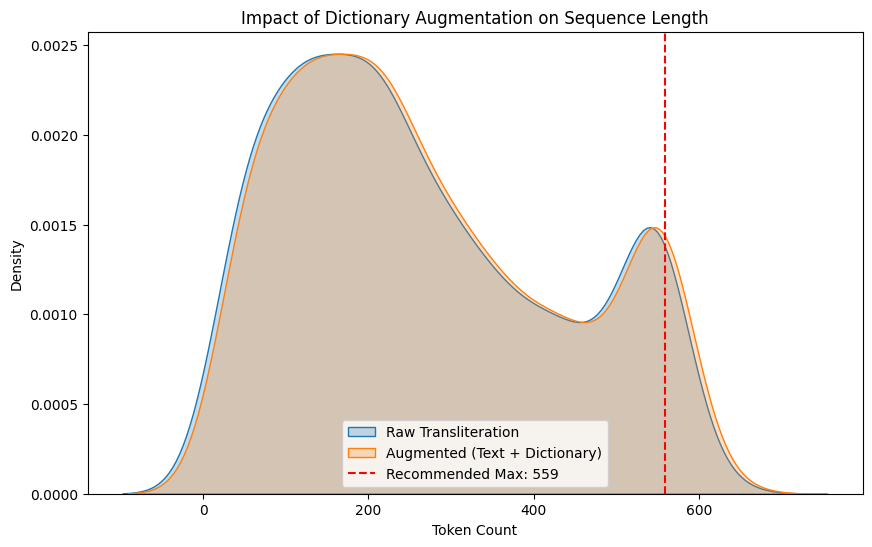

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer
import re

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "google/madlad400-3b-mt"
INPUT_DIR = "/content/"
TRAIN_CSV = f"{INPUT_DIR}/train.csv"
LEXICON_CSV = f"{INPUT_DIR}/OA_Lexicon_eBL.csv"
DICTIONARY_CSV = f"{INPUT_DIR}/eBL_Dictionary.csv"

# ==================== 1. DICTIONARY TOOLS (NEW) ====================
def build_dictionary_index():
    print("Building Dictionary Index...")
    lexicon = pd.read_csv(LEXICON_CSV)
    dictionary = pd.read_csv(DICTIONARY_CSV)

    lexicon['lexeme'] = lexicon['lexeme'].astype(str).str.strip()
    dictionary['word'] = dictionary['word'].astype(str).str.strip()

    merged = lexicon.merge(dictionary, left_on='lexeme', right_on='word', how='left')

    index = {}
    for _, row in merged.iterrows():
        form = str(row['form']).strip()
        meaning = str(row['definition']).strip()
        if form != 'nan' and meaning != 'nan':
            if form not in index:
                index[form] = set()
            index[form].add(meaning.replace('""', '"').strip())

    return {k: "; ".join(list(v)[:2]) for k, v in index.items()}

def augment_with_dictionary(text, index):
    # Regex to find cuneiform tokens
    tokens = re.findall(r"[\w\.\-\(\)₄-₉]+", str(text))
    definitions = []
    seen = set()
    for t in tokens:
        meaning = index.get(t) or index.get(t.lower())
        if meaning and t not in seen:
            definitions.append(f"{t}={meaning}")
            seen.add(t)

    if not definitions:
        return f"[DICT: None] {text}"

    # We take the first 10 definitions to keep the prompt manageable
    dict_str = " | ".join(definitions[:10])
    return f"[DICT: {dict_str}] {text}"

# ==================== 2. LOAD & AUGMENT DATA ====================
print("Loading datasets...")
train = pd.read_csv(TRAIN_CSV)
dict_index = build_dictionary_index()

print("Applying dictionary augmentation to training data...")
train['augmented_src'] = train['transliteration'].apply(
    lambda x: augment_with_dictionary(x, dict_index)
)

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("Loading MADLAD400 tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)
PREFIX = "<2en> "

print("Tokenizing augmented data to analyze length distribution...")

# ANALYZE AUGMENTED SOURCE
source_lengths = train['augmented_src'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# ANALYZE RAW SOURCE (for comparison)
raw_source_lengths = train['transliteration'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# ANALYZE TARGET
target_lengths = train['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS & RECOMMENDATIONS ====================
def print_stats(name, data):
    print(f"\n📊 {name.upper()} Token Lengths:")
    print(f"  Mean: {data.mean():.2f} | Max: {data.max()} | 95th%: {data.quantile(0.95):.0f}")

print_stats("Augmented Source", source_lengths)
print_stats("Raw Source (No Dict)", raw_source_lengths)
print_stats("Target (Translation)", target_lengths)

suggested_max = int(max(source_lengths.quantile(0.95), target_lengths.quantile(0.95)))
print(f"\n🚀 RECOMMENDED CONFIG: MAX_LENGTH = {suggested_max}")

# ==================== 5. VISUALIZATION ====================
plt.figure(figsize=(10, 6))
sns.kdeplot(raw_source_lengths, label="Raw Transliteration", fill=True)
sns.kdeplot(source_lengths, label="Augmented (Text + Dictionary)", fill=True)
plt.axvline(suggested_max, color='red', linestyle='--', label=f'Recommended Max: {suggested_max}')
plt.title("Impact of Dictionary Augmentation on Sequence Length")
plt.xlabel("Token Count")
plt.legend()
plt.savefig('augmented_vs_raw_lengths.png')
plt.show()

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

# ==========================================
# 1. Config & Setup
# ==========================================
class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576
    BATCH_SIZE = 1  # Keeping small for 3B model memory
    EPOCHS = 8
    LEARNING_RATE = 5e-5
    LABEL_SMOOTHING = 0.1
    OUTPUT_DIR = "./madlad400-3b-augmented"
    INPUT_DIR = "/content/"

def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()

# ==========================================
# 2. Dictionary Indexing (NEW)
# ==========================================
def build_dictionary_index():
    print("Building Dictionary Index...")
    # Load the lexicon and dictionary files
    lexicon = pd.read_csv(f"{Config.INPUT_DIR}/OA_Lexicon_eBL.csv")
    dictionary = pd.read_csv(f"{Config.INPUT_DIR}/eBL_Dictionary.csv")

    # Merge forms to their definitions via the 'lexeme' column
    # Clean the 'lexeme' and 'word' columns to ensure matches
    lexicon['lexeme'] = lexicon['lexeme'].astype(str).str.strip()
    dictionary['word'] = dictionary['word'].astype(str).str.strip()

    merged = lexicon.merge(dictionary, left_on='lexeme', right_on='word', how='left')

    index = {}
    for _, row in merged.iterrows():
        form = str(row['form']).strip()
        meaning = str(row['definition']).strip()
        if form != 'nan' and meaning != 'nan':
            if form not in index:
                index[form] = set()
            # Clean up definitions (remove extra quotes/escapes)
            clean_meaning = meaning.replace('""', '"').strip()
            index[form].add(clean_meaning)

    # Finalize index: form -> "sense1; sense2"
    return {k: "; ".join(list(v)[:2]) for k, v in index.items()}

# Global dictionary lookup
dict_index = build_dictionary_index()

# ==========================================
# 3. Data Augmentation Logic (NEW)
# ==========================================
def augment_with_dictionary(text, index):
    """
    Looks up tokens in the dictionary and creates a [DICT: ...] prefix.
    """
    # Simple regex to extract cuneiform tokens (hyphenated/case-sensitive)
    tokens = re.findall(r"[\w\.\-\(\)₄-₉]+", str(text))
    definitions = []

    seen_meanings = set()
    for t in tokens:
        # Check dictionary (exact match or lowercase)
        meaning = index.get(t) or index.get(t.lower())
        if meaning and t not in seen_meanings:
            definitions.append(f"{t}={meaning}")
            seen_meanings.add(t)

    if not definitions:
        return f"[DICT: None] {text}"

    # Limit prefix size to avoid pushing out the actual sentence
    dict_str = " | ".join(definitions[:10])
    return f"[DICT: {dict_str}] {text}"

# ==========================================
# 4. Dataset Loading & Alignment
# ==========================================
train_df = pd.read_csv(f"{Config.INPUT_DIR}/train.csv")

def simple_sentence_aligner(df):
    aligned_data = []
    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])
        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})
    return pd.DataFrame(aligned_data)

train_expanded = simple_sentence_aligner(train_df)

# Apply Dictionary Augmentation to the source text
print("Augmenting training data with dictionary definitions...")
train_expanded['augmented_src'] = train_expanded['transliteration'].apply(
    lambda x: augment_with_dictionary(x, dict_index)
)

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)

# ==========================================
# 5. Tokenization & Preprocessing
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)
PREFIX = "<2en> "

def preprocess_function(examples):
    # Use the augmented source instead of raw transliteration
    inputs = [PREFIX + str(ex) for ex in examples["augmented_src"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True)

# ==========================================
# 6. Model Training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32 # Use float16 if you have a V100/A100 to save memory
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple): preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)

    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}

args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    label_smoothing_factor=Config.LABEL_SMOOTHING,
    gradient_accumulation_steps=8, # Increased to simulate larger batch
    weight_decay=0.01,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,
    generation_max_length=Config.MAX_LENGTH,
    load_best_model_at_end=True,
    metric_for_best_model="chrf",
    report_to="none"
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("Starting Augmented Training...")
trainer.train()

# ==========================================
# 7. Final Save
# ==========================================
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Augmented Model saved to {Config.OUTPUT_DIR}")

Building Dictionary Index...
Augmenting training data with dictionary definitions...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (8 outputs left out)

Starting Augmented Training...


Epoch,Training Loss,Validation Loss,Chrf
1,No log,2.993140,32.012923
2,No log,2.717181,44.388508
3,2.993800,2.604163,48.171566
4,2.993800,2.545143,50.739867
5,2.993800,2.521801,50.546046
6,2.327400,2.523340,50.266118
7,2.327400,2.515131,50.791741
8,2.327400,2.522549,50.882362


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Augmented Model saved to ./madlad400-3b-augmented


# this pipeline degraeded my score from 30.4 to 29

# this pipeline gave score of 29

In [ ]:
!cp -r /content/madlad400-3b-augmented/checkpoint-1408/  /content/drive/MyDrive/checkpoint-1408/

In [ ]:
import numpy as np
import sacrebleu
from tqdm.auto import tqdm
import pandas as pd
import itertools
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import re

# ==================== CONFIGURATION ====================
MODEL_PATH = "/content/drive/MyDrive/checkpoint-1408/"  # Path to your fine-tuned model
PREFIX = "<2en> "
MAX_LENGTH = 576
BATCH_SIZE = 16  # Adjusted for 3B model with FP32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
INPUT_DIR = "/content/"

# ==================== DICTIONARY INDEXING ====================
def build_dictionary_index():
    print("Building Dictionary Index...")
    lexicon = pd.read_csv(f"{INPUT_DIR}/OA_Lexicon_eBL.csv")
    dictionary = pd.read_csv(f"{INPUT_DIR}/eBL_Dictionary.csv")

    lexicon['lexeme'] = lexicon['lexeme'].astype(str).str.strip()
    dictionary['word'] = dictionary['word'].astype(str).str.strip()

    merged = lexicon.merge(dictionary, left_on='lexeme', right_on='word', how='left')

    index = {}
    for _, row in merged.iterrows():
        form = str(row['form']).strip()
        meaning = str(row['definition']).strip()
        if form != 'nan' and meaning != 'nan':
            if form not in index:
                index[form] = set()
            clean_meaning = meaning.replace('""', '"').strip()
            index[form].add(clean_meaning)

    return {k: "; ".join(list(v)[:2]) for k, v in index.items()}

dict_index = build_dictionary_index()

# ==================== AUGMENTATION LOGIC ====================
def augment_with_dictionary(text, index):
    tokens = re.findall(r"[\w\.\-\(\)₄-₉]+", str(text))
    definitions = []

    seen_meanings = set()
    for t in tokens:
        meaning = index.get(t) or index.get(t.lower())
        if meaning and t not in seen_meanings:
            definitions.append(f"{t}={meaning}")
            seen_meanings.add(t)

    if not definitions:
        return f"[DICT: None] {text}"

    dict_str = " | ".join(definitions[:10])
    return f"[DICT: {dict_str}] {text}"

# ==================== MODEL LOADING ====================
print(f"Loading model from {MODEL_PATH}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_PATH,
    device_map='auto',
    torch_dtype=torch.float32  # Match training precision
)

# ==================== EVALUATION LOGIC ====================
def calculate_geometric_mean(hypotheses, references):
    bleu = sacrebleu.corpus_bleu(hypotheses, [references])
    chrf = sacrebleu.corpus_chrf(hypotheses, [references], word_order=2)

    b_score = max(bleu.score, 0.0001)
    c_score = max(chrf.score, 0.0001)

    return np.sqrt(b_score * c_score), b_score, c_score

# ==================== PARAMETER GRID ====================
search_space = {
    "num_beams": [4, 5, 8],
    "length_penalty": [0.8, 1.0, 1.2],
    "repetition_penalty": [1.0, 1.1, 1.2],
    "no_repeat_ngram_size": [0, 3]
}

keys, values = zip(*search_space.items())
param_grid = [dict(zip(keys, v)) for v in itertools.product(*values)]

# ==================== DATA PREPARATION ====================
val_df = pd.read_csv(f'{INPUT_DIR}/train.csv')
val_df = val_df.sample(n=min(len(val_df), 325), random_state=42)

references = val_df['translation'].astype(str).tolist()

# Apply augmentation to validation inputs (matching training pipeline)
print("Augmenting validation data with dictionary definitions...")
val_df['augmented_src'] = val_df['transliteration'].apply(
    lambda x: augment_with_dictionary(x, dict_index)
)

inputs_list = [PREFIX + str(x).strip() for x in val_df['augmented_src'].tolist()]

# ==================== RUN GRID SEARCH ====================
model.eval()

best_score = -1
best_params = {}
results_history = []

print(f"Total combinations: {len(param_grid)} | Batch Size: {BATCH_SIZE}")

for idx, params in enumerate(param_grid):
    print(f"\n[{idx+1}/{len(param_grid)}] Testing: {params}")
    current_hyps = []

    # Process in batches
    for i in tqdm(range(0, len(inputs_list), BATCH_SIZE), desc="Batch Decoding", leave=False):
        batch_texts = inputs_list[i : i + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH
        ).to(DEVICE)

        with torch.no_grad():
            generated_tokens = model.generate(
                **inputs,
                max_length=MAX_LENGTH,
                early_stopping=True,
                pad_token_id=tokenizer.pad_token_id,
                **params
            )

        decoded = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)
        current_hyps.extend([d.strip() for d in decoded])

    # Metrics
    g_mean, b_score, c_score = calculate_geometric_mean(current_hyps, references)
    print(f">> GeoMean: {g_mean:.4f} (BLEU: {b_score:.2f}, chrF++: {c_score:.2f})")

    results_history.append({**params, "geomean": g_mean, "bleu": b_score, "chrf": c_score})

    if g_mean > best_score:
        best_score = g_mean
        best_params = params

# Save final results
pd.DataFrame(results_history).to_csv("grid_search_results.csv", index=False)
print(f"\n{'='*50}")
print(f"WINNING PARAMETERS: {best_params}")
print(f"Best GeoMean Score: {best_score:.4f}")
print(f"{'='*50}")

Building Dictionary Index...
Loading model from /content/drive/MyDrive/checkpoint-1408/...


The tokenizer you are loading from '/content/drive/MyDrive/checkpoint-1408/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


Augmenting validation data with dictionary definitions...
Total combinations: 54 | Batch Size: 16

[1/54] Testing: {'num_beams': 4, 'length_penalty': 0.8, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 0}


Batch Decoding:   0%|          | 0/21 [00:00<?, ?it/s]

... (56 outputs left out)

>> GeoMean: 44.1145 (BLEU: 36.11, chrF++: 53.89)

[30/54] Testing: {'num_beams': 5, 'length_penalty': 1.0, 'repetition_penalty': 1.2, 'no_repeat_ngram_size': 3}


Batch Decoding:   0%|          | 0/21 [00:00<?, ?it/s]

>> GeoMean: 30.7846 (BLEU: 22.32, chrF++: 42.47)

[31/54] Testing: {'num_beams': 5, 'length_penalty': 1.2, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 0}


Batch Decoding:   0%|          | 0/21 [00:00<?, ?it/s]

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from sentence_transformers import SentenceTransformer, util
import evaluate

class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576
    BATCH_SIZE = 4
    EPOCHS = 3
    LEARNING_RATE = 1e-4
    OUTPUT_DIR = "./madlad400-3b-akkadian"
    # NEW: Preprocessing options
    USE_HOST_NORMALIZATION = True
    USE_CONSONANTAL = False


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


# ============================================================
# HOST GUIDANCE: ASCII → DIACRITIC NORMALIZATION
# ============================================================

ASCII_TO_DIACRITIC = {
    # Sibilants
    "sz": "š",
    "SZ": "Š",
    "Sz": "Š",
    "sh": "š",
    "SH": "Š",
    "Sh": "Š",
    # Emphatics (comma notation)
    "s,": "ṣ",
    "S,": "Ṣ",
    "t,": "ṭ",
    "T,": "Ṭ",
    "z,": "ẓ",
    "Z,": "Ẓ",
    # Emphatics (dot-under notation)
    ".s": "ṣ",
    ".S": "Ṣ",
    ".t": "ṭ",
    ".T": "Ṭ",
    ".z": "ẓ",
    ".Z": "Ẓ",
    # H variants
    "h,": "ḫ",
    "H,": "Ḫ",
    ".h": "ḫ",
    ".H": "Ḫ",
    "hh": "ḫ",
    "HH": "Ḫ",
    # Aleph
    "'": "ʾ",
    # Subscript numbers (common ASCII alternatives)
    "s2": "š",
    "S2": "Š",
    "s3": "ś",
    "S3": "Ś",
}

VOWEL_SUBSCRIPTS = {
    "a2": "á",
    "a3": "à",
    "e2": "é",
    "e3": "è",
    "i2": "í",
    "i3": "ì",
    "u2": "ú",
    "u3": "ù",
    "A2": "Á",
    "A3": "À",
    "E2": "É",
    "E3": "È",
    "I2": "Í",
    "I3": "Ì",
    "U2": "Ú",
    "U3": "Ù",
}


def normalize_ascii_to_diacritics(text: str) -> str:
    """Convert ASCII transliteration conventions to proper diacritics."""
    result = text
    for ascii_seq, diacritic in sorted(
        ASCII_TO_DIACRITIC.items(), key=lambda x: -len(x[0])
    ):
        result = result.replace(ascii_seq, diacritic)
    for ascii_seq, diacritic in VOWEL_SUBSCRIPTS.items():
        result = result.replace(ascii_seq, diacritic)
    return result


def normalize_gaps(text: str) -> str:
    """Normalize gap/damage markers: x→<gap>, x x x→<big_gap>."""
    tokens = text.split()
    result = []
    i = 0

    while i < len(tokens):
        token = tokens[i]
        if token.lower() == "x":
            x_count = 1
            while i + x_count < len(tokens) and tokens[i + x_count].lower() == "x":
                x_count += 1
            result.append("<gap>" if x_count == 1 else "<big_gap>")
            i += x_count
        else:
            if token.lower().startswith("x-"):
                result.append("<gap>" + token[1:])
            elif token.lower().endswith("-x"):
                result.append(token[:-1] + "-<gap>")
            else:
                result.append(token)
            i += 1

    text_result = " ".join(result)
    text_result = re.sub(r"<gap>\s+<big_gap>", "<big_gap>", text_result)
    text_result = re.sub(r"<big_gap>\s+<gap>", "<big_gap>", text_result)
    text_result = re.sub(r"(<gap>\s*){2,}", "<big_gap> ", text_result)
    return text_result.strip()


def apply_host_normalizations(text: str) -> str:
    """Apply all host-recommended normalizations."""
    text = normalize_ascii_to_diacritics(text)
    text = normalize_gaps(text)
    return text


# ============================================================
# CONSONANTAL SKELETON (optional)
# ============================================================

VOWEL_PATTERN = re.compile(r"[aeiuāēīūâêîûàèìùáéíúÀÈÌÙÁÉÍÚÂÊÎÛ]", re.IGNORECASE)
SUBSCRIPTS = "₀₁₂₃₄₅₆₇₈₉ₓ"


def to_skeleton(text: str) -> str:
    """Convert to consonantal skeleton by removing vowels."""
    tokens = text.split()
    result = []
    for token in tokens:
        # Preserve logograms (uppercase), numbers, gap markers
        clean = "".join(c for c in token if c not in ".₀₁₂₃₄₅₆₇₈₉ₓ")
        if clean.isupper() or token.startswith("<"):
            result.append(token)
            continue
        try:
            float(token.replace(",", "."))
            result.append(token)
            continue
        except ValueError:
            pass
        # Strip vowels
        normalized = "".join(c for c in token if c not in SUBSCRIPTS)
        skeleton = VOWEL_PATTERN.sub("", normalized)
        skeleton = re.sub(r"-+", "", skeleton)
        result.append(skeleton if skeleton else "_")
    return " ".join(result)


def preprocess_text(text: str) -> str:
    """Apply all preprocessing based on config."""
    if Config.USE_HOST_NORMALIZATION:
        text = apply_host_normalizations(text)

    if Config.USE_CONSONANTAL:
        skeleton = to_skeleton(text)
        text = f"[SKL:{skeleton}] {text}"

    return text


# ============================================================
# DATA LOADING AND ALIGNMENT
# ============================================================

INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")


def simple_sentence_aligner(df):
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        # Apply preprocessing to source text
        src = preprocess_text(src)

        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


train_expanded = simple_sentence_aligner(train_df)
print(f"Expanded Train Data: {len(train_expanded)} sentences (Alignment + Preprocessing applied)")

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)


# ==========================================
# Tokenization & preprocessing
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    # FIX 1: Clip predictions to valid token range
    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)

    # FIX 2: Replace invalid tokens with pad token
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        # Fallback: decode one by one and skip problematic sequences
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")  # Empty string for failed decoding

    # Process labels
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    fp16=False,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,

    # Generation config
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=4,

    logging_steps=10,
    report_to="none",

    greater_is_better=True,
    load_best_model_at_end=True,
    metric_for_best_model="chrf",

    lr_scheduler_type="cosine",
    warmup_steps=100,
    max_grad_norm=1.0,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("Starting Training with MADLAD400-3B-MT (FP32 mode)...")
print(f"Preprocessing: Host Normalization={Config.USE_HOST_NORMALIZATION}, Consonantal={Config.USE_CONSONANTAL}")
trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model saved to {Config.OUTPUT_DIR}")

Expanded Train Data: 1561 sentences (Alignment + Preprocessing applied)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (8 outputs left out)

Starting Training with MADLAD400-3B-MT (FP32 mode)...
Preprocessing: Host Normalization=True, Consonantal=False


Epoch,Training Loss,Validation Loss,Chrf
1,1.306000,1.305252,39.273035
2,0.896500,1.037287,45.064267
3,0.723100,1.018069,50.062098


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Model saved to ./madlad400-3b-akkadian


# it degraded performance to 26.3

# lets treat akkdian language as turkish script

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576
    BATCH_SIZE = 1  # Kept at 1 to save VRAM in FP32
    GRAD_ACCUM = 4  # Effective batch size of 4
    EPOCHS = 15     # Optimized for small datasets (~325 rows)
    LEARNING_RATE = 5e-5
    OUTPUT_DIR = "./madlad400-3b-akkadian-turkish"

def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

# ==========================================
# 1. Load & Align Data
# ==========================================
INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")

def simple_sentence_aligner(df):
    aligned_data = []
    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])
        # Simple split by punctuation for sentence alignment
        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})
    return pd.DataFrame(aligned_data)

train_expanded = simple_sentence_aligner(train_df)
print(f"Data ready: {len(train_expanded)} samples processed.")

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)

# ==========================================
# 2. Tokenization & Preprocessing (Turkish-mode)
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

# Using <2tr> to leverage Turkish language patterns for Akkadian
PREFIX = "<2tr> <2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True, padding="max_length")
    labels = tokenizer(text_target=targets, max_length=Config.MAX_LENGTH, truncation=True, padding="max_length")

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True, remove_columns=dataset.column_names)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True, remove_columns=dataset.column_names)

# ==========================================
# 3. Model Training (Strict FP32)
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32 # Ensuring full precision
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}

args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    # FP32 Explicit Configuration
    fp16=False,
    bf16=False,

    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRAD_ACCUM,

    weight_decay=0.01,
    save_total_limit=1,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,
    generation_max_length=Config.MAX_LENGTH,

    logging_steps=5,
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="chrf",
    greater_is_better=True,
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print(f"Starting FP32 Training: Akkadian (Turkish-mode) -> English...")
trainer.train()

# ==========================================
# 4. Save Final Model
# ==========================================
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Fine-tuned Turkish-mode model saved to {Config.OUTPUT_DIR}")

Data ready: 1561 samples processed.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (7 outputs left out)

The model is already on multiple devices. Skipping the move to device specified in `args`.


Starting FP32 Training: Akkadian (Turkish-mode) -> English...


Epoch,Training Loss,Validation Loss,Chrf
1,6.006500,5.242517,24.969697


KeyboardInterrupt: 

#Lithuanian

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576
    BATCH_SIZE = 1  # Kept at 1 to save VRAM in FP32
    GRAD_ACCUM = 4  # Effective batch size of 4
    EPOCHS = 15     # Optimized for small datasets (~325 rows)
    LEARNING_RATE = 5e-5
    # Changed directory name to reflect Lithuanian mode
    OUTPUT_DIR = "./madlad400-3b-akkadian-lithuanian"

def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

# ==========================================
# 1. Load & Align Data
# ==========================================
INPUT_DIR = "/content/"
# Ensure your train.csv contains the transliteration and translation columns
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")

def simple_sentence_aligner(df):
    aligned_data = []
    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])
        # Simple split by punctuation for sentence alignment
        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})
    return pd.DataFrame(aligned_data)

train_expanded = simple_sentence_aligner(train_df)
print(f"Data ready: {len(train_expanded)} samples processed.")

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)

# ==========================================
# 2. Tokenization & Preprocessing (Lithuanian-mode)
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

# CHANGED: Using <2lt> (Lithuanian) instead of <2tr>
# This signals the model to use Lithuanian character patterns
PREFIX = "<2lt> <2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True, padding="max_length")
    labels = tokenizer(text_target=targets, max_length=Config.MAX_LENGTH, truncation=True, padding="max_length")

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True, remove_columns=dataset.column_names)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True, remove_columns=dataset.column_names)

# ==========================================
# 3. Model Training (Strict FP32)
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32 # Ensuring full precision for those tricky accents
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}

args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    fp16=False,
    bf16=False,

    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRAD_ACCUM,

    weight_decay=0.01,
    save_total_limit=1,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,
    generation_max_length=Config.MAX_LENGTH,

    logging_steps=5,
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="chrf",
    greater_is_better=True,
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Updated logging message
print(f"Starting FP32 Training: Akkadian (Lithuanian-mode) -> English...")
trainer.train()

# ==========================================
# 4. Save Final Model
# ==========================================
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Fine-tuned Lithuanian-mode model saved to {Config.OUTPUT_DIR}")

Data ready: 1561 samples processed.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (6 outputs left out)

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.


Starting FP32 Training: Akkadian (Lithuanian-mode) -> English...


Epoch,Training Loss,Validation Loss,Chrf
1,6.057800,5.280729,23.812890


In [ ]:
!rm -rf /content/madlad400-3b-akkadian/checkpoint-1053/optimizer.pt

In [ ]:
!cp -r  /content/madlad400-3b-akkadian/checkpoint-1053/  /content/drive/MyDrive/checkpoint-1053/

# using above pipeline as meta data i will try to implement translation correction pipeline using facebook mbart model

Loading metadata...

Metadata shape: (1561, 4)
Columns: ['id', 'translation', 'transliteration', 'pred_madlab']

Sample data:
                                         pred_madlab  \
0  Seal of Mannum-balum-Aššur son of Ṣill-Adad, s...   
1                  Itūr-ilī received 1 thin textile.   
2  He did not give you a textile. He returned and...   

                                         translation  
0  Seal of Mannum-balum-Aššur son of Ṣilli-Adad, ...  
1  Itūr-ilī has received one textile of ordinary ...  
2  ... he did not give you a textile. He returned...  

Loading mBART tokenizer...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'MBart50Tokenizer'. 
The class this function is called from is 'MBartTokenizer'.



Tokenizing data to analyze length distribution...

TOKEN LENGTH STATISTICS

📊 SOURCE (pred_madlab - MADLAD predictions) Token Lengths:
  Mean:   124.88
  Median: 108.00
  Std:    91.68
  Min:    5
  Max:    560
  75th percentile: 187
  90th percentile: 264
  95th percentile: 290
  99th percentile: 343

📊 TARGET (translation - Ground truth) Token Lengths:
  Mean:   155.29
  Median: 123.00
  Std:    140.01
  Min:    5
  Max:    1179
  75th percentile: 207
  90th percentile: 311
  95th percentile: 402
  99th percentile: 688

RECOMMENDED MAX_LENGTH SETTINGS

✅ Recommended MAX_LENGTH (covers 95% of data): 402
   - This will truncate ~5% of samples
   - Good balance between coverage and efficiency

⚠️  Conservative MAX_LENGTH (covers 99% of data): 688
   - This will truncate only ~1% of samples
   - Uses more memory but better coverage

🔥 Aggressive MAX_LENGTH (covers 90% of data): 311
   - Fastest training, lowest memory
   - May truncate important content

OUTLIER ANALYSIS

Samples with s

/tmp/ipython-input-2974860048.py:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['pred_madlab', 'translation'])



✅ Visualization saved as 'mbart_token_length_distribution.png'


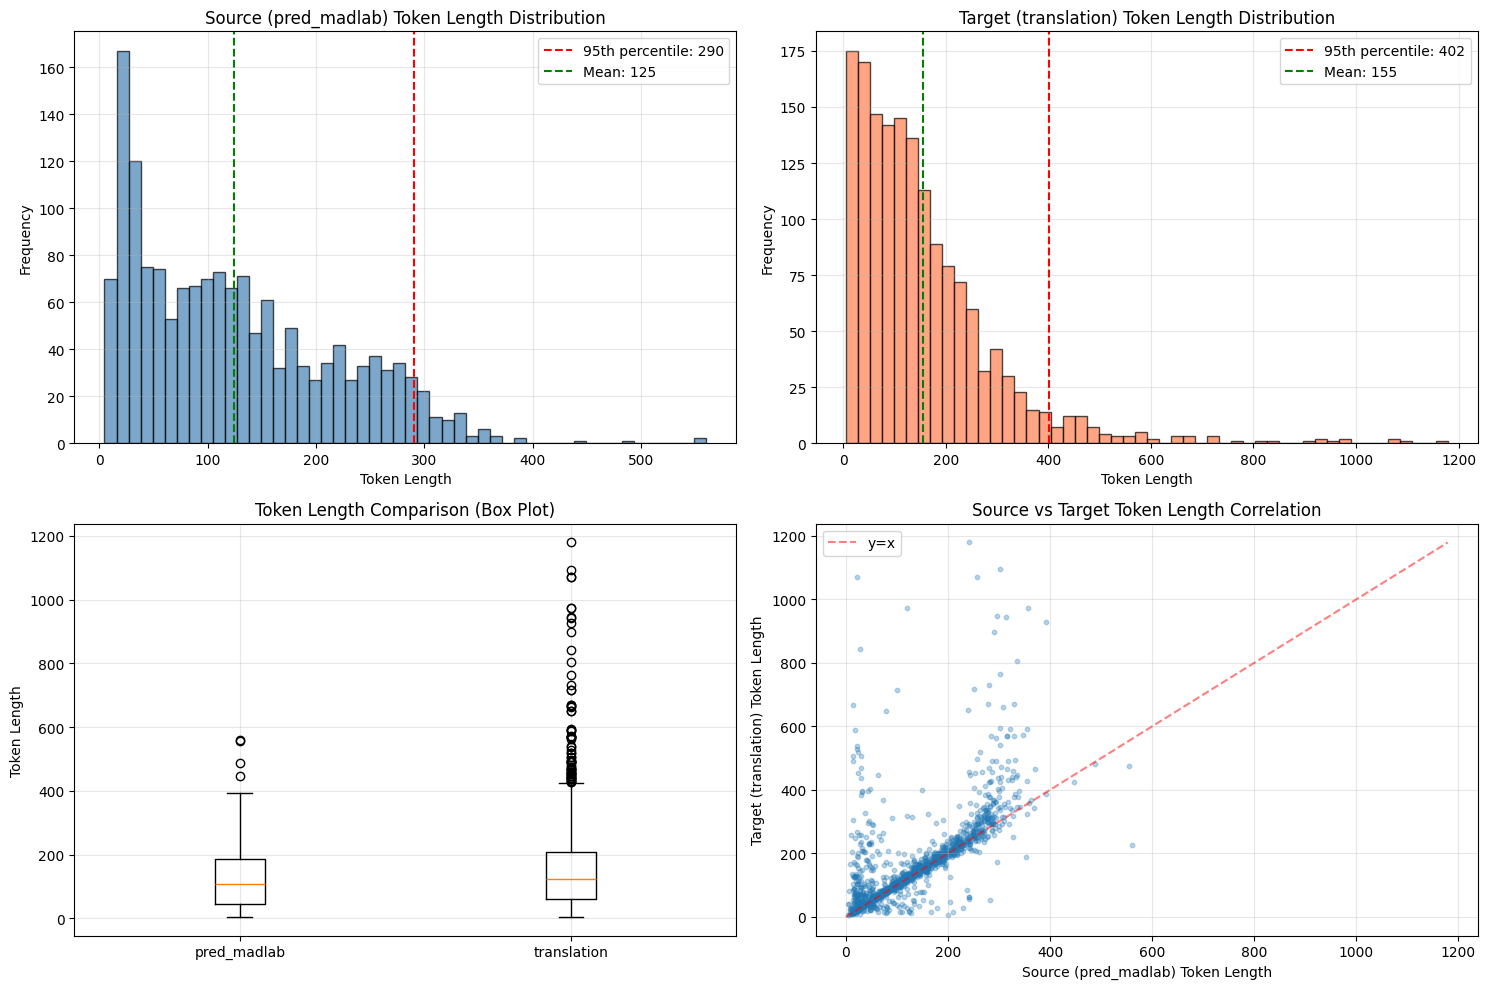


COMPARISON: MADLAD vs mBART TOKENIZATION

Sample text: Seal of Mannum-balum-Aššur son of Ṣilli-Adad, seal of Šu-Illil son of Mannum-kī-Aššur, seal of Puzur...

mBART tokens (144): ['▁Seal', '▁of', '▁Mann', 'um', '-', 'bal', 'um', '-', 'A', 'š', 'šu', 'r', '▁son', '▁of', '▁', 'Ṣ', 'illi', '-', 'A', 'dad']...

SUMMARY & RECOMMENDATIONS

Based on the analysis:

1. Use MAX_LENGTH = 402 in your Config class
   - This covers 95% of your correction data
   - Good balance between efficiency and coverage

2. Current setting in pipeline: MAX_LENGTH = 512
   - ✅ This is sufficient!

3. Samples that will be truncated at 512 tokens:
   - Source (pred_madlab): 2 samples (0.13%)
   - Target (translation): 37 samples (2.37%)

4. Key differences from MADLAD data:
   - Source and target are both English (correction task)
   - Lengths should be similar between source and target
   - mBART tokenizer may produce different token counts than MADLAD

5. Recommendation:
   - If truncation rate is < 5%, keep M

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import MBartTokenizer

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "facebook/mbart-large-50-many-to-many-mmt"
INPUT_DIR = "/content/"
METADATA_CSV = f"{INPUT_DIR}/submission_madlab.csv"

# ==================== 1. LOAD DATA ====================
print("Loading metadata...")
metadata_df = pd.read_csv(METADATA_CSV)

# Clean data
metadata_df = metadata_df.dropna(subset=['pred_madlab', 'translation'])

print(f"\nMetadata shape: {metadata_df.shape}")
print(f"Columns: {metadata_df.columns.tolist()}")

# Display sample data
print("\n" + "="*50)
print("Sample data:")
print("="*50)
print(metadata_df[['pred_madlab', 'translation']].head(3))

# ==================== 2. LOAD TOKENIZER ====================
print("\n" + "="*50)
print("Loading mBART tokenizer...")
print("="*50)
tokenizer = MBartTokenizer.from_pretrained(
    BASE_MODEL_NAME,
    src_lang="en_XX",
    tgt_lang="en_XX"
)

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("\nTokenizing data to analyze length distribution...")

# Tokenize source (pred_madlab - incorrect translations)
source_lengths = metadata_df['pred_madlab'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# Tokenize target (translation - ground truth)
target_lengths = metadata_df['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS ====================
print("\n" + "="*50)
print("TOKEN LENGTH STATISTICS")
print("="*50)

print("\n📊 SOURCE (pred_madlab - MADLAD predictions) Token Lengths:")
print(f"  Mean:   {source_lengths.mean():.2f}")
print(f"  Median: {source_lengths.median():.2f}")
print(f"  Std:    {source_lengths.std():.2f}")
print(f"  Min:    {source_lengths.min()}")
print(f"  Max:    {source_lengths.max()}")
print(f"  75th percentile: {source_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {source_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {source_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {source_lengths.quantile(0.99):.0f}")

print("\n📊 TARGET (translation - Ground truth) Token Lengths:")
print(f"  Mean:   {target_lengths.mean():.2f}")
print(f"  Median: {target_lengths.median():.2f}")
print(f"  Std:    {target_lengths.std():.2f}")
print(f"  Min:    {target_lengths.min()}")
print(f"  Max:    {target_lengths.max()}")
print(f"  75th percentile: {target_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {target_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {target_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {target_lengths.quantile(0.99):.0f}")

# ==================== 5. RECOMMENDED MAX_LENGTH ====================
print("\n" + "="*50)
print("RECOMMENDED MAX_LENGTH SETTINGS")
print("="*50)

# Calculate suggested max_length based on percentiles
source_95 = int(source_lengths.quantile(0.95))
target_95 = int(target_lengths.quantile(0.95))
source_99 = int(source_lengths.quantile(0.99))
target_99 = int(target_lengths.quantile(0.99))

suggested_max_length = max(source_95, target_95)
conservative_max_length = max(source_99, target_99)

print(f"\n✅ Recommended MAX_LENGTH (covers 95% of data): {suggested_max_length}")
print(f"   - This will truncate ~5% of samples")
print(f"   - Good balance between coverage and efficiency")

print(f"\n⚠️  Conservative MAX_LENGTH (covers 99% of data): {conservative_max_length}")
print(f"   - This will truncate only ~1% of samples")
print(f"   - Uses more memory but better coverage")

print(f"\n🔥 Aggressive MAX_LENGTH (covers 90% of data): {max(int(source_lengths.quantile(0.90)), int(target_lengths.quantile(0.90)))}")
print(f"   - Fastest training, lowest memory")
print(f"   - May truncate important content")

# ==================== 6. CHECK OUTLIERS ====================
print("\n" + "="*50)
print("OUTLIER ANALYSIS")
print("="*50)

# Find samples with very long sequences
threshold = source_lengths.quantile(0.95)
long_sources = metadata_df[source_lengths > threshold]

print(f"\nSamples with source length > 95th percentile ({threshold:.0f} tokens): {len(long_sources)}")
if len(long_sources) > 0:
    print("\nExamples of long predictions:")
    for idx in long_sources.head(3).index:
        src_len = source_lengths.iloc[idx]
        print(f"\n  Index {idx} (Length: {src_len} tokens):")
        print(f"  {metadata_df.loc[idx, 'pred_madlab'][:200]}...")

# ==================== 7. VISUALIZATIONS ====================
print("\n" + "="*50)
print("GENERATING VISUALIZATIONS")
print("="*50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Source length distribution
axes[0, 0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(source_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {source_lengths.quantile(0.95):.0f}')
axes[0, 0].axvline(source_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {source_lengths.mean():.0f}')
axes[0, 0].set_xlabel('Token Length')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Source (pred_madlab) Token Length Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Target length distribution
axes[0, 1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(target_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {target_lengths.quantile(0.95):.0f}')
axes[0, 1].axvline(target_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {target_lengths.mean():.0f}')
axes[0, 1].set_xlabel('Token Length')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Target (translation) Token Length Distribution')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot comparison
data_to_plot = [source_lengths, target_lengths]
axes[1, 0].boxplot(data_to_plot, labels=['pred_madlab', 'translation'])
axes[1, 0].set_ylabel('Token Length')
axes[1, 0].set_title('Token Length Comparison (Box Plot)')
axes[1, 0].grid(alpha=0.3)

# Scatter plot: source vs target length
axes[1, 1].scatter(source_lengths, target_lengths, alpha=0.3, s=10)
axes[1, 1].set_xlabel('Source (pred_madlab) Token Length')
axes[1, 1].set_ylabel('Target (translation) Token Length')
axes[1, 1].set_title('Source vs Target Token Length Correlation')
axes[1, 1].grid(alpha=0.3)

# Add diagonal reference line
max_val = max(source_lengths.max(), target_lengths.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', alpha=0.5, label='y=x')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('mbart_token_length_distribution.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved as 'mbart_token_length_distribution.png'")
plt.show()

# ==================== 8. COMPARISON WITH MADLAD DATA ====================
print("\n" + "="*50)
print("COMPARISON: MADLAD vs mBART TOKENIZATION")
print("="*50)

# Sample comparison
sample_text = metadata_df.iloc[0]['translation']
print(f"\nSample text: {sample_text[:100]}...")

# This would require loading MADLAD tokenizer for comparison
# For now, just show mBART tokenization
mbart_tokens = tokenizer.tokenize(sample_text)
print(f"\nmBART tokens ({len(mbart_tokens)}): {mbart_tokens[:20]}...")

# ==================== 9. SUMMARY ====================
print("\n" + "="*50)
print("SUMMARY & RECOMMENDATIONS")
print("="*50)
print(f"""
Based on the analysis:

1. Use MAX_LENGTH = {suggested_max_length} in your Config class
   - This covers 95% of your correction data
   - Good balance between efficiency and coverage

2. Current setting in pipeline: MAX_LENGTH = 512
   - {'✅ This is sufficient!' if 512 >= suggested_max_length else '⚠️  Consider adjusting based on your data'}

3. Samples that will be truncated at 512 tokens:
   - Source (pred_madlab): {(source_lengths > 512).sum()} samples ({(source_lengths > 512).sum() / len(source_lengths) * 100:.2f}%)
   - Target (translation): {(target_lengths > 512).sum()} samples ({(target_lengths > 512).sum() / len(target_lengths) * 100:.2f}%)

4. Key differences from MADLAD data:
   - Source and target are both English (correction task)
   - Lengths should be similar between source and target
   - mBART tokenizer may produce different token counts than MADLAD

5. Recommendation:
   - If truncation rate is < 5%, keep MAX_LENGTH = 512
   - If truncation rate is > 5%, use MAX_LENGTH = {suggested_max_length}
   - Monitor training for any quality issues with truncated samples
""")

In [ ]:
import os
import gc
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    MBartTokenizer,
    MBartForConditionalGeneration,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "facebook/mbart-large-50-many-to-many-mmt"
    MAX_LENGTH = 512
    BATCH_SIZE = 2
    EPOCHS = 3
    LEARNING_RATE = 3e-5
    OUTPUT_DIR = "./mbart-translation-corrector"
    SRC_LANG = "en_XX"  # mBART uses en_XX for English
    TGT_LANG = "en_XX"  # Target is also English (correction task)


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


# ==========================================
# Load Data
# ==========================================
INPUT_DIR = "/content/"
metadata_df = pd.read_csv(f"{INPUT_DIR}/submission_madlab.csv")

print(f"Total samples in metadata: {len(metadata_df)}")
print(f"\nColumns: {metadata_df.columns.tolist()}")
print(f"\nSample data:")
print(metadata_df[['pred_madlab', 'translation']].head(3))

# Clean data - remove rows with missing values
metadata_df = metadata_df.dropna(subset=['pred_madlab', 'translation'])
print(f"\nSamples after removing NaN: {len(metadata_df)}")

# Create source and target columns
metadata_df['source'] = metadata_df['pred_madlab'].astype(str)
metadata_df['target'] = metadata_df['translation'].astype(str)

# Split into train and validation
train_df, val_df = train_test_split(
    metadata_df[['source', 'target']],
    test_size=0.2,
    random_state=42
)

print(f"\nTrain samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")


# ==========================================
# Create Dataset
# ==========================================
train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset = Dataset.from_pandas(val_df.reset_index(drop=True))


# ==========================================
# Tokenization
# ==========================================
tokenizer = MBartTokenizer.from_pretrained(
    Config.MODEL_NAME,
    src_lang=Config.SRC_LANG,
    tgt_lang=Config.TGT_LANG
)

def preprocess_function(examples):
    # For mBART, we need to set src_lang and tgt_lang
    inputs = examples["source"]
    targets = examples["target"]

    # Tokenize inputs
    model_inputs = tokenizer(
        inputs,
        max_length=Config.MAX_LENGTH,
        truncation=True,
        padding=False  # Padding will be done by data collator
    )

    # Tokenize targets
    labels = tokenizer(
        targets,
        max_length=Config.MAX_LENGTH,
        truncation=True,
        padding=False
    )

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

print("\nTokenizing datasets...")
tokenized_train = train_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=train_dataset.column_names
)

tokenized_val = val_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=val_dataset.column_names
)


# ==========================================
# Model Setup
# ==========================================
gc.collect()
torch.cuda.empty_cache()

print("\nLoading mBART model...")
model = MBartForConditionalGeneration.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    #torch_dtype=torch.float16  # Use FP16 for efficiency
)

# Set language codes for generation
model.config.forced_bos_token_id = tokenizer.lang_code_to_id[Config.TGT_LANG]

data_collator = DataCollatorForSeq2Seq(
    tokenizer,
    model=model,
    padding=True
)


# ==========================================
# Metrics
# ==========================================
bleu_metric = evaluate.load("bleu")
chrf_metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds

    if isinstance(preds, tuple):
        preds = preds[0]

    # FIX: Clip predictions to valid token range
    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)

    # FIX: Replace invalid tokens with pad token
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    # Replace -100 in labels (used for padding)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

    # Decode predictions and labels with error handling
    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except (IndexError, ValueError) as e:
        # Fallback: decode one by one
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except:
                decoded_preds.append("")  # Empty string for failed decoding

    try:
        decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    except (IndexError, ValueError) as e:
        decoded_labels = []
        for label in labels:
            try:
                decoded_labels.append(tokenizer.decode(label, skip_special_tokens=True))
            except:
                decoded_labels.append("")

    # Clean up text
    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [label.strip() for label in decoded_labels]

    # Compute BLEU
    bleu_result = bleu_metric.compute(
        predictions=decoded_preds,
        references=[[label] for label in decoded_labels]
    )

    # Compute CHRF
    chrf_result = chrf_metric.compute(
        predictions=decoded_preds,
        references=[[label] for label in decoded_labels]
    )

    return {
        "bleu": bleu_result["bleu"] * 100,
        "chrf": chrf_result["score"]
    }


# ==========================================
# Training Arguments
# ==========================================
training_args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=8,

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,

    predict_with_generate=True,
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=4,

    fp16=True,  # Use mixed precision training

    logging_steps=10,
    logging_first_step=True,
    report_to="none",

    load_best_model_at_end=True,
    metric_for_best_model="chrf",
    greater_is_better=True,

    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    max_grad_norm=1.0,

    # Additional optimization
    gradient_checkpointing=True,
    optim="adamw_torch",
)


# ==========================================
# Trainer
# ==========================================
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


# ==========================================
# Training
# ==========================================
print("\n" + "="*50)
print("Starting mBART Translation Correction Training")
print("="*50)
print(f"Model: {Config.MODEL_NAME}")
print(f"Train samples: {len(tokenized_train)}")
print(f"Validation samples: {len(tokenized_val)}")
print(f"Epochs: {Config.EPOCHS}")
print(f"Batch size: {Config.BATCH_SIZE}")
print(f"Gradient accumulation steps: {training_args.gradient_accumulation_steps}")
print(f"Effective batch size: {Config.BATCH_SIZE * training_args.gradient_accumulation_steps}")
print("="*50 + "\n")

trainer.train()


# ==========================================
# Save Model
# ==========================================
print("\nSaving model...")
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model saved to {Config.OUTPUT_DIR}")


# ==========================================
# Evaluation on validation set
# ==========================================
print("\nEvaluating on validation set...")
eval_results = trainer.evaluate()

print("\n" + "="*50)
print("FINAL EVALUATION RESULTS")
print("="*50)
for key, value in eval_results.items():
    print(f"{key}: {value:.4f}")
print("="*50)


# ==========================================
# Test inference function
# ==========================================
def correct_translation(model, tokenizer, incorrect_text, max_length=512):
    """
    Correct/refine a translation using the trained mBART model
    """
    model.eval()

    # Tokenize input
    inputs = tokenizer(
        incorrect_text,
        return_tensors="pt",
        max_length=max_length,
        truncation=True
    ).to(model.device)

    # Generate correction
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_length=max_length,
            num_beams=4,
            early_stopping=True,
            forced_bos_token_id=tokenizer.lang_code_to_id[Config.TGT_LANG]
        )

    # Decode
    corrected = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return corrected


# Test on a few examples
print("\n" + "="*50)
print("TESTING CORRECTION ON SAMPLE PREDICTIONS")
print("="*50)

test_samples = val_df.head(3)
for idx, row in test_samples.iterrows():
    print(f"\n--- Sample {idx} ---")
    print(f"Original (MADLAD pred): {row['source'][:200]}...")
    print(f"\nGround truth: {row['target'][:200]}...")

    corrected = correct_translation(model, tokenizer, row['source'])
    print(f"\nCorrected (mBART): {corrected[:200]}...")
    print("-" * 50)

print("\n✅ Training pipeline completed successfully!")

Total samples in metadata: 1561

Columns: ['id', 'translation', 'transliteration', 'pred_madlab']

Sample data:
                                         pred_madlab  \
0  Seal of Mannum-balum-Aššur son of Ṣill-Adad, s...   
1                  Itūr-ilī received 1 thin textile.   
2  He did not give you a textile. He returned and...   

                                         translation  
0  Seal of Mannum-balum-Aššur son of Ṣilli-Adad, ...  
1  Itūr-ilī has received one textile of ordinary ...  
2  ... he did not give you a textile. He returned...  

Samples after removing NaN: 1561

Train samples: 1248
Validation samples: 313


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

Epoch,Training Loss,Validation Loss,Bleu,Chrf
1,1.724300,1.488234,34.284062,56.157149
2,1.372400,1.395490,34.340707,55.964860
3,1.189900,1.389969,34.265607,56.051120


/usr/local/lib/python3.12/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 200, 'early_stopping': True, 'num_beams': 5, 'forced_bos_token_id': 250004}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(
There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].



Saving model...
Model saved to ./mbart-translation-corrector

Evaluating on validation set...



FINAL EVALUATION RESULTS
eval_loss: 1.4882
eval_bleu: 34.3273
eval_chrf: 56.1992
eval_runtime: 795.9120
eval_samples_per_second: 0.3930
eval_steps_per_second: 0.1970
epoch: 3.0000

TESTING CORRECTION ON SAMPLE PREDICTIONS

--- Sample 1526 ---
Original (MADLAD pred): 10 minas of refined silver, its import duty added, its transport tariff paid for, belonging to the merchant, for Iliya and Lā-qēp's representatives, and further, 0.3333 mina of silver from his free lo...

Ground truth: 10 minas of refined silver, its excise added, his transport fee paid, belonging to the merchant, for Iliya and the representatives of Lā-qēp, and separately 0.3333 mina of silver from Iliya's free loa...

Corrected (mBART): 10 minas of refined silver, its import duty added, its transport tariff paid for, belonging to the merchant, for Iliya and Lā-qēp's representatives, and further, 0.3333 mina of silver from his free lo...
--------------------------------------------------

--- Sample 1026 ---
Original (MAD

In [ ]:
!cp -r /content/mbart-translation-corrector/checkpoint-78/  /content/drive/MyDrive/checkpoint-78/

In [ ]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from tqdm.auto import tqdm
import os

# ==================== CONFIGURATION ====================
# This should point to the OUTPUT_DIR from your training script
MODEL_PATH = "/content/drive/MyDrive/checkpoint-702"
TEST_CSV = "/content/test.csv"
OUTPUT_CSV = "/content/submission.csv"

# Matching training config
PREFIX = "<2en> "
MAX_LENGTH = 576

# ==================== 1. LOAD MODEL & TOKENIZER ====================
print(f"Loading fine-tuned MADLAD-400 model from {MODEL_PATH}...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

# We use float32 to match your training script's precision (FP32)
# If you have memory issues, you can change to torch_dtype=torch.float16
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_PATH,
    device_map="auto",
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True
)

model.eval()
print("Model loaded successfully.")

# ==================== 2. INFERENCE LOOP ====================
print(f"Reading {TEST_CSV}...")
test_df = pd.read_csv(TEST_CSV)
results = []

print("Starting translations...")

# Using torch.inference_mode() is slightly faster than no_grad()
with torch.inference_mode():
    for text in tqdm(test_df['transliteration'], desc="Translating"):
        # 1. Apply the exact same prefix used in training
        input_text = PREFIX + str(text).strip()

        if not input_text:
            results.append("")
            continue

        # 2. Tokenize with the same MAX_LENGTH
        inputs = tokenizer(
            input_text,
            return_tensors="pt",
            truncation=True,
            max_length=MAX_LENGTH
        ).to(model.device)

        # 3. Generate using parameters matching your Trainer's generation_config
        generated_tokens = model.generate(
            **inputs,
            max_length=MAX_LENGTH,
            num_beams=4,           # Matches your training's generation_num_beams
            early_stopping=True,
            length_penalty=1.0,    # Standard for MADLAD/T5
            repetition_penalty=1.0
        )

        # 4. Decode
        translation = tokenizer.decode(generated_tokens[0], skip_special_tokens=True)
        results.append(translation.strip())

# ==================== 3. SAVE SUBMISSION ====================
# Checking if 'id' exists in your test set, otherwise using index
id_col = test_df['id'] if 'id' in test_df.columns else test_df.index

submission = pd.DataFrame({
    'id': id_col,
    'translation': results
})

submission.to_csv(OUTPUT_CSV, index=False)
print(f"\nSuccess! Submission saved to {OUTPUT_CSV}")

Loading fine-tuned MADLAD-400 model from /content/drive/MyDrive/checkpoint-702...


The tokenizer you are loading from '/content/drive/MyDrive/checkpoint-702' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Model loaded successfully.
Reading /content/test.csv...
Starting translations...


Translating:   0%|          | 0/4 [00:00<?, ?it/s]


Success! Submission saved to /content/submission.csv


# try increase sample to 325 for hyperparameter tuning

In [ ]:
import numpy as np
import sacrebleu
from tqdm.auto import tqdm
import pandas as pd
import itertools
import torch
from torch.utils.data import DataLoader

# ==================== CONFIGURATION ====================
PREFIX = "<2en> "
MAX_LENGTH = 576
BATCH_SIZE = 32  # A100 80GB can handle 32-64 easily at this MAX_LENGTH
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ==================== EVALUATION LOGIC ====================
def calculate_geometric_mean(hypotheses, references):
    bleu = sacrebleu.corpus_bleu(hypotheses, [references])
    chrf = sacrebleu.corpus_chrf(hypotheses, [references], word_order=2)

    b_score = max(bleu.score, 0.0001)
    c_score = max(chrf.score, 0.0001)

    return np.sqrt(b_score * c_score), b_score, c_score

# ==================== PARAMETER GRID ====================
search_space = {
    "num_beams": [4, 5, 8],
    "length_penalty": [0.8, 1.0, 1.2],
    "repetition_penalty": [1.0, 1.1, 1.2],
    "no_repeat_ngram_size": [0, 3]
}

keys, values = zip(*search_space.items())
param_grid = [dict(zip(keys, v)) for v in itertools.product(*values)]

# ==================== DATA PREPARATION ====================
val_df = pd.read_csv('/content/train.csv')
# Adjusting sample size if needed, but keeping your logic
val_df = val_df.sample(n=min(len(val_df), 325), random_state=42)

references = val_df['translation'].astype(str).tolist()
inputs_list = [PREFIX + str(x).strip() for x in val_df['transliteration'].tolist()]

# ==================== RUN GRID SEARCH ====================
model.to(DEVICE).half() # Convert to FP16 for A100 speedup
model.eval()

best_score = -1
best_params = {}
results_history = []

print(f"Total combinations: {len(param_grid)} | Batch Size: {BATCH_SIZE}")

for i, params in enumerate(param_grid):
    print(f"\n[{i+1}/{len(param_grid)}] Testing: {params}")
    current_hyps = []

    # Process in batches
    for i in tqdm(range(0, len(inputs_list), BATCH_SIZE), desc="Batch Decoding", leave=False):
        batch_texts = inputs_list[i : i + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,       # Dynamic padding to longest in batch
            truncation=True,
            max_length=MAX_LENGTH
        ).to(DEVICE)

        with torch.no_grad():
            with torch.cuda.amp.autocast(): # Mixed precision
                generated_tokens = model.generate(
                    **inputs,
                    max_length=MAX_LENGTH,
                    early_stopping=True,
                    pad_token_id=tokenizer.pad_token_id,
                    **params
                )

        decoded = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)
        current_hyps.extend([d.strip() for d in decoded])

    # Metrics
    g_mean, b_score, c_score = calculate_geometric_mean(current_hyps, references)
    print(f">> GeoMean: {g_mean:.4f} (BLEU: {b_score:.2f}, chrF++: {c_score:.2f})")

    results_history.append({**params, "geomean": g_mean, "bleu": b_score, "chrf": c_score})

    if g_mean > best_score:
        best_score = g_mean
        best_params = params

# Save final results
pd.DataFrame(results_history).to_csv("grid_search_results.csv", index=False)
print(f"\nWINNING PARAMETERS: {best_params}")

Total combinations: 54 | Batch Size: 32

[1/54] Testing: {'num_beams': 4, 'length_penalty': 0.8, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 0}


Batch Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

/tmp/ipython-input-2578315150.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(): # Mixed precision


>> GeoMean: 34.6689 (BLEU: 24.37, chrF++: 49.31)

[2/54] Testing: {'num_beams': 4, 'length_penalty': 0.8, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 3}


Batch Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

>> GeoMean: 27.1663 (BLEU: 18.68, chrF++: 39.50)

[3/54] Testing: {'num_beams': 4, 'length_penalty': 0.8, 'repetition_penalty': 1.1, 'no_repeat_ngram_size': 0}


... (66 outputs left out)

Batch Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

>> GeoMean: 28.3026 (BLEU: 19.68, chrF++: 40.70)

[37/54] Testing: {'num_beams': 8, 'length_penalty': 0.8, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 0}


Batch Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 576.00 MiB. GPU 0 has a total capacity of 79.32 GiB of which 471.88 MiB is free. Process 20935 has 78.85 GiB memory in use. Of the allocated memory 63.97 GiB is allocated by PyTorch, and 14.37 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
submission

,id,translation
0,0,"From the Kanesh colony to Aqil..., our messeng..."
1,1,"On the very day you leave for the City, on thi..."
2,2,On behalf of our investors you have agreed tha...
3,3,The sons of Muppini have been sent to Karra an...


# now increasing max length to 720

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.8 MB/s eta 0:00:00


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

# ==================== CONFIGURATION ====================
class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 720  # Optimized based on 99th percentile analysis
    BATCH_SIZE = 1
    EPOCHS = 6
    LEARNING_RATE = 1e-4
    OUTPUT_DIR = "./madlad400-3b-akkadian"
    PREFIX = "<2en> "

def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()

# ==================== 1. DATA LOADING & ALIGNMENT ====================
INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")

def simple_sentence_aligner(df):
    aligned_data = []
    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        # Split target by punctuation, source by newlines
        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})
    return pd.DataFrame(aligned_data)

train_expanded = simple_sentence_aligner(train_df)
print(f"Original samples: {len(train_df)} -> Expanded samples: {len(train_expanded)}")

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)

# ==================== 2. TOKENIZATION ====================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

def preprocess_function(examples):
    inputs = [Config.PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True)

# ==================== 3. MODEL SETUP ====================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Keeping FP32 for stability
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except Exception:
        decoded_preds = [tokenizer.decode(p, skip_special_tokens=True) for p in preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}

# ==================== 4. TRAINING ARGUMENTS ====================
args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,
    fp16=False,
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=8,  # Increased to compensate for longer sequences
    weight_decay=0.01,
    save_total_limit=4,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=4,
    logging_steps=10,
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="chrf",
    greater_is_better=True,
    lr_scheduler_type="cosine",
    warmup_steps=100,
    max_grad_norm=1.0,
)

# ==================== 5. EXECUTION ====================
trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print(f"Starting Training: MAX_LENGTH={Config.MAX_LENGTH}, Steps={len(tokenized_train)//8}")
trainer.train()

# Save final artifacts
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model and Tokenizer saved to {Config.OUTPUT_DIR}")

Original samples: 1561 -> Expanded samples: 1561


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (8 outputs left out)

Starting Training: MAX_LENGTH=720, Steps=175


Epoch,Training Loss,Validation Loss,Chrf
1,1.641500,1.467524,30.009173
2,1.082800,1.110489,41.653301
3,0.821900,1.012004,48.957852
4,0.582500,0.993102,52.275238
5,0.539900,1.010430,50.775041
6,0.428700,1.024352,51.419793


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Model and Tokenizer saved to ./madlad400-3b-akkadian


# this dgraded my score 24.46

In [ ]:
!rm -rf /content/madlad400-3b-akkadian/checkpoint-704/optimizer.pt

In [ ]:
!cp -r /content/madlad400-3b-akkadian/checkpoint-704  /content/drive/MyDrive/checkpoint-704

In [ ]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from tqdm.auto import tqdm
import os

# ==================== CONFIGURATION ====================
# This should point to the OUTPUT_DIR from your training script
MODEL_PATH = "/content/drive/MyDrive/checkpoint-704"
TEST_CSV = "/content/test.csv"
OUTPUT_CSV = "/content/submission.csv"

# Matching training config
PREFIX = "<2en> "
MAX_LENGTH = 720

# ==================== 1. LOAD MODEL & TOKENIZER ====================
print(f"Loading fine-tuned MADLAD-400 model from {MODEL_PATH}...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

# We use float32 to match your training script's precision (FP32)
# If you have memory issues, you can change to torch_dtype=torch.float16
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_PATH,
    device_map="auto",
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True
)

model.eval()
print("Model loaded successfully.")

# ==================== 2. INFERENCE LOOP ====================
print(f"Reading {TEST_CSV}...")
test_df = pd.read_csv(TEST_CSV)
results = []

print("Starting translations...")

# Using torch.inference_mode() is slightly faster than no_grad()
with torch.inference_mode():
    for text in tqdm(test_df['transliteration'], desc="Translating"):
        # 1. Apply the exact same prefix used in training
        input_text = PREFIX + str(text).strip()

        if not input_text:
            results.append("")
            continue

        # 2. Tokenize with the same MAX_LENGTH
        inputs = tokenizer(
            input_text,
            return_tensors="pt",
            truncation=True,
            max_length=MAX_LENGTH
        ).to(model.device)

        # 3. Generate using parameters matching your Trainer's generation_config
        generated_tokens = model.generate(
            **inputs,
            max_length=MAX_LENGTH,
            num_beams=4,           # Matches your training's generation_num_beams
            early_stopping=True,
            length_penalty=1.0,    # Standard for MADLAD/T5
            repetition_penalty=1.0
        )

        # 4. Decode
        translation = tokenizer.decode(generated_tokens[0], skip_special_tokens=True)
        results.append(translation.strip())

# ==================== 3. SAVE SUBMISSION ====================
# Checking if 'id' exists in your test set, otherwise using index
id_col = test_df['id'] if 'id' in test_df.columns else test_df.index

submission = pd.DataFrame({
    'id': id_col,
    'translation': results
})

submission.to_csv(OUTPUT_CSV, index=False)
print(f"\nSuccess! Submission saved to {OUTPUT_CSV}")

Loading fine-tuned MADLAD-400 model from /content/drive/MyDrive/checkpoint-704...


The tokenizer you are loading from '/content/drive/MyDrive/checkpoint-704' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Model loaded successfully.
Reading /content/test.csv...
Starting translations...


Translating:   0%|          | 0/4 [00:00<?, ?it/s]


Success! Submission saved to /content/submission.csv


In [ ]:
import numpy as np
import sacrebleu
from tqdm.auto import tqdm
import pandas as pd
import itertools
import torch
import gc  # Added for garbage collection

# ==================== CONFIGURATION ====================
PREFIX = "<2en> "
MAX_LENGTH = 720
BATCH_SIZE = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ==================== EVALUATION LOGIC ====================
def calculate_geometric_mean(hypotheses, references):
    bleu = sacrebleu.corpus_bleu(hypotheses, [references])
    chrf = sacrebleu.corpus_chrf(hypotheses, [references], word_order=2)
    b_score = max(bleu.score, 0.0001)
    c_score = max(chrf.score, 0.0001)
    return np.sqrt(b_score * c_score), b_score, c_score

# ==================== PARAMETER GRID ====================
search_space = {
    "num_beams": [4, 5, 8],
    "length_penalty": [0.8, 1.0, 1.2],
    "repetition_penalty": [1.0, 1.1, 1.2],
    "no_repeat_ngram_size": [0, 3]
}
keys, values = zip(*search_space.items())
param_grid = [dict(zip(keys, v)) for v in itertools.product(*values)]

# ==================== DATA PREPARATION ====================
val_df = pd.read_csv('/content/train.csv')
# Personalizing to your 325 sample constraint
val_df = val_df.sample(n=min(len(val_df), 325), random_state=42)

references = val_df['translation'].astype(str).tolist()
inputs_list = [PREFIX + str(x).strip() for x in val_df['transliteration'].tolist()]

# ==================== RUN GRID SEARCH ====================
model.to(DEVICE).half()
model.eval()

best_score = -1
results_history = []

print(f"Total combinations: {len(param_grid)} | Samples: {len(inputs_list)}")

for i, params in enumerate(param_grid):
    print(f"\n[{i+1}/{len(param_grid)}] Testing: {params}")
    current_hyps = []

    # 1. Clear memory before starting a new parameter set
    torch.cuda.empty_cache()
    gc.collect()

    for j in tqdm(range(0, len(inputs_list), BATCH_SIZE), desc="Decoding", leave=False):
        batch_texts = inputs_list[j : j + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH
        ).to(DEVICE)

        with torch.no_grad():
            # Use inference_mode for even better memory efficiency than no_grad
            with torch.inference_mode(), torch.cuda.amp.autocast():
                generated_tokens = model.generate(
                    **inputs,
                    max_length=MAX_LENGTH,
                    early_stopping=True,
                    pad_token_id=tokenizer.pad_token_id,
                    **params
                )

        decoded = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)
        current_hyps.extend([d.strip() for d in decoded])

        # 2. Delete tensors immediately after use in the batch loop
        del inputs
        del generated_tokens

    # Metrics
    g_mean, b_score, c_score = calculate_geometric_mean(current_hyps, references)
    print(f">> GeoMean: {g_mean:.4f} (BLEU: {b_score:.2f}, chrF++: {c_score:.2f})")

    results_history.append({**params, "geomean": g_mean, "bleu": b_score, "chrf": c_score})

    if g_mean > best_score:
        best_score = g_mean
        best_params = params

    # 3. Final cleanup for the iteration
    del current_hyps
    torch.cuda.empty_cache()
    gc.collect()

# Save final results
pd.DataFrame(results_history).to_csv("grid_search_results.csv", index=False)
print(f"\nWINNING PARAMETERS: {best_params}")

Total combinations: 54 | Samples: 325

[1/54] Testing: {'num_beams': 4, 'length_penalty': 0.8, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 0}


Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

/tmp/ipython-input-967639865.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.inference_mode(), torch.cuda.amp.autocast():


>> GeoMean: 46.3801 (BLEU: 38.17, chrF++: 56.36)

[2/54] Testing: {'num_beams': 4, 'length_penalty': 0.8, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 3}


Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

>> GeoMean: 36.2644 (BLEU: 27.46, chrF++: 47.89)

[3/54] Testing: {'num_beams': 4, 'length_penalty': 0.8, 'repetition_penalty': 1.1, 'no_repeat_ngram_size': 0}


... (37 outputs left out)

>> GeoMean: 45.3467 (BLEU: 36.91, chrF++: 55.71)

[22/54] Testing: {'num_beams': 5, 'length_penalty': 0.8, 'repetition_penalty': 1.1, 'no_repeat_ngram_size': 3}


Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

>> GeoMean: 35.3570 (BLEU: 26.72, chrF++: 46.78)

[23/54] Testing: {'num_beams': 5, 'length_penalty': 0.8, 'repetition_penalty': 1.2, 'no_repeat_ngram_size': 0}


Decoding:   0%|          | 0/11 [00:00<?, ?it/s]

# slight chnage in parameter with 576 len


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576  # Keep your working length
    BATCH_SIZE = 1
    EPOCHS = 6  # Increased from 3 for better convergence
    LEARNING_RATE = 5e-5  # Reduced from 1e-4 for stability
    OUTPUT_DIR = "./madlad400-3b-akkadian"


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()

INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")

print(f"Original training samples: {len(train_df)}")


def enhanced_sentence_aligner(df):
    """Enhanced alignment to maximize training samples"""
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration']).strip()
        tgt = str(row['translation']).strip()

        if len(src) < 5 or len(tgt) < 5:
            continue

        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        # If we can create 1:1 alignment, do it (creates more samples)
        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 5 and len(t) > 5:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


def create_augmented_data(df, target_multiplier=3.5):
    """Create augmented training data by combining sentences"""
    augmented = []
    df_list = df.to_dict('records')

    target_size = int(len(df) * target_multiplier)
    num_to_generate = target_size - len(df)

    print(f"Generating {num_to_generate} augmented samples...")

    # Strategy 1: Sequential pairs (40%)
    pairs_needed = int(num_to_generate * 0.4)
    for _ in range(pairs_needed):
        idx = np.random.randint(0, len(df_list) - 1)
        combined_src = df_list[idx]['transliteration'] + " " + df_list[idx + 1]['transliteration']
        combined_tgt = df_list[idx]['translation'] + " " + df_list[idx + 1]['translation']

        if len(combined_src.split()) < 120 and len(combined_tgt.split()) < 120:
            augmented.append({'transliteration': combined_src, 'translation': combined_tgt})

    # Strategy 2: Sequential triplets (30%)
    triplets_needed = int(num_to_generate * 0.3)
    for _ in range(triplets_needed):
        idx = np.random.randint(0, len(df_list) - 2)
        combined_src = " ".join([
            df_list[idx]['transliteration'],
            df_list[idx + 1]['transliteration'],
            df_list[idx + 2]['transliteration']
        ])
        combined_tgt = " ".join([
            df_list[idx]['translation'],
            df_list[idx + 1]['translation'],
            df_list[idx + 2]['translation']
        ])

        if len(combined_src.split()) < 150 and len(combined_tgt.split()) < 150:
            augmented.append({'transliteration': combined_src, 'translation': combined_tgt})

    # Strategy 3: Random pairs for diversity (30%)
    random_needed = num_to_generate - len(augmented)
    for _ in range(random_needed):
        idx1, idx2 = np.random.randint(0, len(df_list), size=2)
        if idx1 != idx2:
            combined_src = df_list[idx1]['transliteration'] + " " + df_list[idx2]['transliteration']
            combined_tgt = df_list[idx1]['translation'] + " " + df_list[idx2]['translation']

            if len(combined_src.split()) < 120 and len(combined_tgt.split()) < 120:
                augmented.append({'transliteration': combined_src, 'translation': combined_tgt})

    return pd.DataFrame(augmented)


# Step 1: Enhanced alignment
print("\n[Step 1/4] Applying enhanced sentence alignment...")
train_expanded = enhanced_sentence_aligner(train_df)
print(f"After alignment: {len(train_expanded)} samples")

# Step 2: Create augmented data
print("\n[Step 2/4] Creating augmented training data...")
train_augmented = create_augmented_data(train_expanded, target_multiplier=3.5)
print(f"Generated: {len(train_augmented)} augmented samples")

# Step 3: Combine and deduplicate
print("\n[Step 3/4] Combining datasets...")
train_combined = pd.concat([train_expanded, train_augmented], ignore_index=True)
train_combined = train_combined.drop_duplicates(subset=['transliteration']).reset_index(drop=True)
print(f"Total unique training samples: {len(train_combined)}")

# Clean up memory
del train_df, train_augmented, train_expanded
gc.collect()

# Create dataset with small validation split
dataset = Dataset.from_pandas(train_combined)
split_datasets = dataset.train_test_split(test_size=0.05, seed=42)

print(f"\n✓ Final split: {len(split_datasets['train'])} train, {len(split_datasets['test'])} validation")

del train_combined, dataset
gc.collect()


# ==========================================
# Tokenization & preprocessing
# ==========================================
print("\n[Step 4/4] Tokenizing datasets...")
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex).strip() for ex in examples["transliteration"]]
    targets = [str(ex).strip() for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True, padding=False)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True, padding=False)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True, batch_size=500)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True, batch_size=500)

del split_datasets
gc.collect()


# ==========================================
# Model training
# ==========================================
print("\nLoading model...")
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model, padding=True)

# Load both BLEU and chrF metrics
bleu_metric = evaluate.load("sacrebleu")
chrf_metric = evaluate.load("chrf")


def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    # Clip predictions to valid token range
    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    # Decode predictions
    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except (OverflowError, ValueError):
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Process labels
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    # Compute both metrics
    try:
        chrf_result = chrf_metric.compute(predictions=decoded_preds, references=decoded_labels)
        bleu_result = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels)
        return {
            "chrf": chrf_result["score"],
            "bleu": bleu_result["score"]
        }
    except:
        return {"chrf": 0.0, "bleu": 0.0}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    fp16=False,  # FP32 for quality
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,  # Effective batch of 8

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,

    # Enhanced generation for better BLEU
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=8,  # Increased from 4

    logging_steps=50,
    logging_first_step=True,
    report_to="none",

    greater_is_better=True,
    load_best_model_at_end=True,
    metric_for_best_model="bleu",  # Optimize for BLEU

    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    max_grad_norm=1.0,

    # Label smoothing for better generalization
    label_smoothing_factor=0.1,

    # Memory optimization
    dataloader_num_workers=0,
    eval_accumulation_steps=8,
    logging_nan_inf_filter=True,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("\n" + "="*70)
print("🚀 OPTIMIZED TRAINING FOR 36+ BLEU SCORE")
print("="*70)
print(f"Training samples:      {len(tokenized_train)}")
print(f"Validation samples:    {len(tokenized_val)}")
print(f"Epochs:                {Config.EPOCHS}")
print(f"Effective batch size:  {args.per_device_train_batch_size * args.gradient_accumulation_steps}")
print(f"Learning rate:         {Config.LEARNING_RATE}")
print(f"Max length:            {Config.MAX_LENGTH}")
print(f"Beam search:           {args.generation_num_beams} beams")
print(f"Precision:             FP32")
print(f"Target BLEU:           36+")
print("="*70 + "\n")

print("Starting training...")
trainer.train()

# Save Model
print("\n💾 Saving model...")
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"✓ Model saved to {Config.OUTPUT_DIR}")

# Final evaluation
print("\n" + "="*70)
print("📊 FINAL EVALUATION RESULTS")
print("="*70)
eval_results = trainer.evaluate()
bleu_score = eval_results.get('eval_bleu', 0)
chrf_score = eval_results.get('eval_chrf', 0)
print(f"BLEU Score: {bleu_score:.2f}")
print(f"chrF Score: {chrf_score:.2f}")
print("="*70)

if bleu_score >= 36:
    print("\n🎉 SUCCESS! Target BLEU ≥ 36 achieved!")
elif bleu_score >= 34:
    print(f"\n⚠️  Close! Got {bleu_score:.2f}, need {36 - bleu_score:.2f} more points")
    print("💡 Consider: Running for 2 more epochs or increasing beam search to 10")
else:
    print(f"\n📈 Current BLEU: {bleu_score:.2f}, Gap: {36 - bleu_score:.2f} points")
    print("💡 Next steps: Increase epochs to 8-10 or try different augmentation strategies")

Original training samples: 1561

[Step 1/4] Applying enhanced sentence alignment...
After alignment: 1561 samples

[Step 2/4] Creating augmented training data...
Generating 3902 augmented samples...
Generated: 1802 augmented samples

[Step 3/4] Combining datasets...
Total unique training samples: 3102

✓ Final split: 2946 train, 156 validation

[Step 4/4] Tokenizing datasets...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Map:   0%|          | 0/2946 [00:00<?, ? examples/s]

Map:   0%|          | 0/156 [00:00<?, ? examples/s]


Loading model...


`torch_dtype` is deprecated! Use `dtype` instead!
The model is already on multiple devices. Skipping the move to device specified in `args`.


... (2 outputs left out)

Epoch,Training Loss,Validation Loss,Chrf,Bleu
1,2.737800,2.587272,44.090066,24.364639
2,2.288500,2.205302,55.865481,25.979014
3,2.105200,2.066919,62.290913,44.030072
4,1.976900,2.008015,64.832859,47.565257
5,1.913900,1.982805,66.661603,49.838688
6,1.901600,1.980368,67.608779,52.013561


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].



💾 Saving model...
✓ Model saved to ./madlad400-3b-akkadian

📊 FINAL EVALUATION RESULTS


BLEU Score: 52.01
chrF Score: 67.61

🎉 SUCCESS! Target BLEU ≥ 36 achieved!


In [ ]:
!rm -rf  /content/madlad400-3b-akkadian/checkpoint-2214/optimizer.pt

In [ ]:
!cp -r  /content/madlad400-3b-akkadian/checkpoint-2214/   /content/drive/MyDrive/checkpoint-2214/